# Singapore's birth rate: group analysis

AN6100 · Exploring potential factors behind Singapore's falling total fertility rate (TFR).

| Part | Factor | Presenter |
|---|---|---|
| 1 | Healthcare | Zhou Dianfeng |
| 2 | Housing | Angelica Wu |
| 3 | Marriage | Tongtong Tang |
| 4 | Income & inequality | Wang Gaoyang |
| 5 | Education | Huang Yixuan |

All five parts read one dataset, `Fertility_Combined_Data.csv` (one row per year, 2000–2025). Each part's original code, figures and insights are kept; only the line that loads data now reads the combined file. Saved outputs are the original figures.

**How to run:** keep this notebook, `Fertility_Combined_Data.csv` and the `sections/` folder together, install `requirements.txt`, then choose **Restart Kernel and Run All**.


## Combined dataset

| Columns | Content | Used by |
|---|---|---|
| `Year` … `Gov_Health_%_GDP` | Group master table: TFR, age-specific fertility, marriage, income, housing indices, education and healthcare indicators | Education (all), Marriage, shared TFR |
| `PM_Avg`, `PM_Median`, `CPI_All_Items_*`, `PM_*_Real_2010`, `Real_Growth_*`, `Gini_*` | Income: income per member (17872), CPI (M213751), real income, real growth by decile (17885, M810361), Gini (17892) | Income |
| `resident_live_births_number` … `general_households_health_inflation_2019base_pct` | Healthcare-only indicators (CPI 2024 = 100, fees, doctors, nurses, hospital beds, inflation) | Healthcare |
| `ASFR_45_49`, `HDB_Resale_Index_Q1`–`Q4`, `Private_Landed_Index_URA`, `Private_Non_Landed_Index_URA` | Housing-only inputs: fertility at 45–49, quarterly HDB resale index, original URA private indices | Housing |

Columns that held identical values in several parts (for example TFR) are stored once. Blank cells are years with no published value.

In [1]:
from pathlib import Path
import os
import pandas as pd

# Locate the project folder (the folder that contains the combined dataset).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Fertility_Combined_Data.csv').is_file())
COMBINED = pd.read_csv(ROOT / 'Fertility_Combined_Data.csv', float_precision='round_trip')

# Each section reads its own columns from the one combined dataset, under the column names its code expects.
SECTIONS = {
    'healthcare': dict(years=(2010, 2025), integer=['year', 'resident_live_births_number'], columns={
        'Year': 'year', 'TFR': 'tfr_per_female',
        'resident_live_births_number': 'resident_live_births_number',
        'cpi_health_2024_100': 'cpi_health_2024_100',
        'cpi_medicines_health_products_2024_100': 'cpi_medicines_health_products_2024_100',
        'cpi_outpatient_care_2024_100': 'cpi_outpatient_care_2024_100',
        'cpi_inpatient_care_2024_100': 'cpi_inpatient_care_2024_100',
        'cpi_other_health_services_2024_100': 'cpi_other_health_services_2024_100',
        'cpi_health_insurance_2024_100': 'cpi_health_insurance_2024_100',
        'cpi_polyclinic_fees_2024_100': 'cpi_polyclinic_fees_2024_100',
        'cpi_gp_fees_2024_100': 'cpi_gp_fees_2024_100',
        'cpi_specialist_outpatient_fees_2024_100': 'cpi_specialist_outpatient_fees_2024_100',
        'gov_health_development_sgd_million': 'gov_health_development_sgd_million',
        'gov_health_operating_sgd_million': 'gov_health_operating_sgd_million',
        'doctors_per_10000_total_population': 'doctors_per_10000_total_population',
        'nurses_per_10000_total_population': 'nurses_per_10000_total_population',
        'acute_hospital_beds_total_number': 'acute_hospital_beds_total_number',
        'acute_hospital_beds_public_number': 'acute_hospital_beds_public_number',
        'acute_hospital_beds_nonprofit_number': 'acute_hospital_beds_nonprofit_number',
        'acute_hospital_beds_private_number': 'acute_hospital_beds_private_number',
        'acute_hospitals_public_number': 'acute_hospitals_public_number',
        'acute_hospitals_private_number': 'acute_hospitals_private_number',
        'public_polyclinics_number': 'public_polyclinics_number',
        'young_children_health_inflation_2019base_pct': 'young_children_health_inflation_2019base_pct',
        'general_households_health_inflation_2019base_pct': 'general_households_health_inflation_2019base_pct',
        'Gov_Health_per_Capita': 'gov_health_per_capita_sgd',
        'Gov_Health_Total': 'gov_health_expenditure_sgd_million',
        'Gov_Health_%_GDP': 'gov_health_expenditure_gdp_pct',
        'HES_Health_Monthly': 'hes_all_households_health_monthly_sgd',
        'HES_Health_Share_%': 'hes_all_households_health_share_pct'},
        order=['year',
               'tfr_per_female',
               'resident_live_births_number',
               'cpi_health_2024_100',
               'cpi_medicines_health_products_2024_100',
               'cpi_outpatient_care_2024_100',
               'cpi_inpatient_care_2024_100',
               'cpi_other_health_services_2024_100',
               'cpi_health_insurance_2024_100',
               'cpi_polyclinic_fees_2024_100',
               'cpi_gp_fees_2024_100',
               'cpi_specialist_outpatient_fees_2024_100',
               'gov_health_per_capita_sgd',
               'gov_health_expenditure_sgd_million',
               'gov_health_expenditure_gdp_pct',
               'gov_health_development_sgd_million',
               'gov_health_operating_sgd_million',
               'doctors_per_10000_total_population',
               'nurses_per_10000_total_population',
               'hes_all_households_health_monthly_sgd',
               'hes_all_households_health_share_pct',
               'acute_hospital_beds_total_number',
               'acute_hospital_beds_public_number',
               'acute_hospital_beds_nonprofit_number',
               'acute_hospital_beds_private_number',
               'acute_hospitals_public_number',
               'acute_hospitals_private_number',
               'public_polyclinics_number',
               'young_children_health_inflation_2019base_pct',
               'general_households_health_inflation_2019base_pct']),
    'housing_hdb_quarterly': dict(years=(2000, 2025), integer=['Year'], columns={
        'Year': 'Year', 'HDB_Resale_Index_Q4': '4', 'HDB_Resale_Index_Q3': '3',
        'HDB_Resale_Index_Q2': '2', 'HDB_Resale_Index_Q1': '1'}),
    'housing_fertility': dict(years=(2000, 2025), integer=['Year'], columns={
        'Year': 'Year', 'TFR': 'Total_Fertility_Rate',
        **{f'ASFR_{a}_{a + 4}': f'{a} - {a + 4} Years' for a in range(15, 50, 5)}}),
    'housing_private': dict(years=(2000, 2025), integer=['Year'], columns={
        'Year': 'Year', 'Private_Landed_Index_URA': 'Private_Landed_Index',
        'Private_Non_Landed_Index_URA': 'Private_Non_Landed_Index'}),
    'marriage': dict(years=(2000, 2025), integer=['Year'], columns={c: c for c in [
        'Year', 'TFR', 'F_Marriage_Rate_20_24', 'F_Marriage_Rate_25_29', 'F_Marriage_Rate_30_34',
        'F_Marriage_Rate_35_39', 'F_Marriage_Rate_40_44', 'Median_Age_First_Birth', 'Brides_25_29', 'Brides_30_34']}),
    'income': dict(years=(2010, 2025), integer=['Year'], columns={c: c for c in ['Year', 'TFR', 'PM_Avg', 'PM_Median', 'CPI_All_Items_2024_100', 'CPI_All_Items_2010_100', 'PM_Avg_Real_2010', 'PM_Median_Real_2010', 'Real_Growth_%', 'Real_Growth_D1', 'Real_Growth_D2', 'Real_Growth_D3', 'Real_Growth_D4', 'Real_Growth_D5', 'Real_Growth_D6', 'Real_Growth_D7', 'Real_Growth_D8', 'Real_Growth_D9', 'Gini_Before_Transfers', 'Gini_After_Transfers', 'Real_Growth_D1_M810361', 'Real_Growth_D10_M810361']}),
    'education': dict(years=(2000, 2025), integer=['Year'],
                      columns={c: c for c in COMBINED.loc[:, 'Year':'Gov_Health_%_GDP'].columns}),
}


def load_section(name):
    spec = SECTIONS[name]
    y0, y1 = spec['years']
    frame = COMBINED.loc[COMBINED.Year.between(y0, y1), list(spec['columns'])]
    frame = frame.rename(columns=spec['columns']).reset_index(drop=True)
    if spec.get('order'):
        frame = frame[spec['order']]
    for column in spec['integer']:
        frame[column] = frame[column].astype('int64')
    return frame


print(f'Combined dataset: {COMBINED.shape[0]} years × {COMBINED.shape[1]} columns')

Combined dataset: 26 years × 111 columns


# Part 1 · Healthcare

Presenter: Zhou Dianfeng

Original data file `data/healthcare_2010_2025.csv` is now read from `Fertility_Combined_Data.csv` with identical values.

In [2]:
# Healthcare tables and figures are saved under sections/healthcare/analysis_outputs.
(ROOT / 'sections' / 'healthcare').mkdir(parents=True, exist_ok=True)
os.chdir(ROOT / 'sections' / 'healthcare')

# Healthcare and fertility in Singapore

This notebook describes healthcare prices, household spending and government expenditure, then compares healthcare CPI with total fertility rate (TFR). The analysis uses annual data from 2010 to 2025 supplied for the group project.

Run the notebook from the project folder with **Restart Kernel and Run All**. It reads `data/healthcare_2010_2025.csv` and saves tables and figures under `analysis_outputs`. Dependencies and dashboard instructions are in `README.md`.

The CSV is the starting dataset. No web extraction is performed. Its numeric values were retained from the supplied file; source definitions and publication status have not been independently verified. TFR is measured in children per woman, not births per 1,000 people. The analysis is descriptive, with one exploratory correlation comparison.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 12)
OUT = Path('analysis_outputs')
OUT.mkdir(exist_ok=True)
def show_chart(name):
    fig = plt.gcf()
    fig.tight_layout()
    fig.savefig(OUT / (name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
def explain(text): display(Markdown(text))

In [4]:
# Combined notebook: read the healthcare columns from Fertility_Combined_Data.csv.
raw = load_section('healthcare')
if 'year' not in raw.columns:
    raise ValueError('The dataset must include a year column.')

# Reject invalid values instead of silently replacing them with missing data.
data = raw.apply(pd.to_numeric, errors='raise')
if data.year.isna().any() or (data.year % 1 != 0).any():
    raise ValueError('Years must be non-missing integers.')
if data.year.duplicated().any():
    raise ValueError('Duplicate years must be resolved before analysis.')
data.year = data.year.astype(int)
df = data.sort_values('year').set_index('year')
observed_years = df.index.tolist()
df = df.reindex(range(df.index.min(), df.index.max()+1))
df.index.name = 'year'
if np.isinf(df.to_numpy()).any():
    raise ValueError('Infinite values are not valid observations.')

cleaning_log = pd.DataFrame({
    'check': ['Source rows', 'Source fields', 'Duplicate rows', 'Duplicate years',
              'Missing cells before processing', 'Missing cells after processing', 'Added calendar years'],
    'result': [len(raw), len(raw.columns), int(raw.duplicated().sum()),
               int(data.year.duplicated().sum()), int(raw.isna().sum().sum()),
               int(df.isna().sum().sum()), len(df)-len(raw)]
})
display(cleaning_log)
print(f'Time range: {df.index.min()}–{df.index.max()}')
display(raw.head())
cleaning_log.to_csv(OUT/'cleaning_log.csv', index=False)
df.to_csv(OUT/'healthcare_clean.csv', index_label='year')


,check,result
0,Source rows,16
1,Source fields,30
2,Duplicate rows,0
3,Duplicate years,0
4,Missing cells before processing,75
5,Missing cells after processing,75
6,Added calendar years,0


Time range: 2010–2025


,year,tfr_per_female,resident_live_births_number,cpi_health_2024_100,cpi_medicines_health_products_2024_100,cpi_outpatient_care_2024_100,...,acute_hospital_beds_private_number,acute_hospitals_public_number,acute_hospitals_private_number,public_polyclinics_number,young_children_health_inflation_2019base_pct,general_households_health_inflation_2019base_pct
0,2010,1.15,35129,74.092,89.621,78.144,...,1095.0,8.0,6.0,18.0,NaN,NaN
1,2011,1.20,36178,75.868,92.066,79.853,...,1096.0,8.0,6.0,18.0,NaN,NaN
2,2012,1.29,38641,79.281,94.770,83.915,...,1272.0,8.0,8.0,18.0,NaN,NaN
3,2013,1.19,35681,82.374,97.151,86.787,...,1279.0,8.0,8.0,18.0,NaN,NaN
4,2014,1.25,37967,84.722,98.116,88.495,...,1327.0,8.0,9.0,18.0,NaN,NaN


**Data checks.** The supplied file contains 16 annual observations and 30 fields, covering 2010–2025 without duplicate or absent years. Missing observations are retained.

## Rebase the six CPI series to 2010 = 100

For each category, the new index equals **original index in year t / original index in 2010 × 100**. The source CSV remains unchanged. The six calculated columns use the suffix `_2010_100`; all charts and calculations for these categories use the rebased columns. The separate fee series that do not have 2010 observations retain their original base and are not included in the six-category box plot.

Rebasing changes index levels and index-point differences. It does not change annual percentage growth or Pearson correlation with TFR. No values are rounded before calculation.

In [5]:
# Use the full dataset's 2010 observations, regardless of the displayed year range.
CPI_COLUMNS = {'cpi_health_2024_100': 'cpi_health_2010_100', 'cpi_medicines_health_products_2024_100': 'cpi_medicines_health_products_2010_100', 'cpi_outpatient_care_2024_100': 'cpi_outpatient_care_2010_100', 'cpi_inpatient_care_2024_100': 'cpi_inpatient_care_2010_100', 'cpi_other_health_services_2024_100': 'cpi_other_health_services_2010_100', 'cpi_health_insurance_2024_100': 'cpi_health_insurance_2010_100'}
if 2010 not in df.index:
    raise ValueError('The 2010 baseline year is missing.')
base_values = df.loc[2010, list(CPI_COLUMNS)]
if base_values.isna().any() or (base_values <= 0).any():
    raise ValueError('Each CPI series needs a positive, observed 2010 baseline.')
source_cpi = df[list(CPI_COLUMNS)].copy()
rebased_cpi = source_cpi.div(base_values).mul(100).rename(columns=CPI_COLUMNS)
df = df.drop(columns=list(CPI_COLUMNS)).join(rebased_cpi)

assert np.allclose(rebased_cpi.loc[2010], 100)
old_growth = source_cpi.div(source_cpi.shift(1)).sub(1)
new_growth = rebased_cpi.div(rebased_cpi.shift(1)).sub(1)
assert np.allclose(old_growth.to_numpy(), new_growth.to_numpy(), equal_nan=True)
baseline_check = pd.DataFrame({
    'source_column': list(CPI_COLUMNS),
    'rebased_column': list(CPI_COLUMNS.values()),
    'original_2010_value': base_values.to_numpy(),
    'rebased_2010_value': rebased_cpi.loc[2010].to_numpy(),
    'rebased_2025_value': rebased_cpi.loc[2025].to_numpy()
})
display(baseline_check.round(4))
baseline_check.to_csv(OUT/'cpi_baseline_check.csv', index=False)
rebased_cpi.to_csv(OUT/'cpi_2010_base.csv', index_label='year')
df.to_csv(OUT/'healthcare_clean.csv', index_label='year')
df.to_csv(OUT/'healthcare_2010_2025_rebased.csv', index_label='year')


,source_column,rebased_column,original_2010_value,rebased_2010_value,rebased_2025_value
0,cpi_health_2024_100,cpi_health_2010_100,74.092,100.0,138.5480
1,cpi_medicines_health_products_2024_100,cpi_medicines_health_products_2010_100,89.621,100.0,110.5611
2,cpi_outpatient_care_2024_100,cpi_outpatient_care_2010_100,78.144,100.0,127.6285
3,cpi_inpatient_care_2024_100,cpi_inpatient_care_2010_100,62.599,100.0,159.5696
4,cpi_other_health_services_2024_100,cpi_other_health_services_2010_100,65.159,100.0,156.6307
5,cpi_health_insurance_2024_100,cpi_health_insurance_2010_100,75.996,100.0,148.2696


**Rebasing check.** All six categories equal 100 in 2010. 

## Data checks and descriptive statistics

Columns are checked for numeric values and years are checked for duplicates. Rows are sorted by year, and any absent calendar years are inserted as missing rows so annual changes never span an unobserved year. No values are imputed, removed or adjusted for inflation.

The summary below covers the indicators used in the report. Means and standard deviations describe variation across observed years, not variation across people. Household spending has only three survey waves, and government spending ends in 2023.

In [6]:
labels = {
    'cpi_health_2010_100': 'Healthcare CPI (2010=100)',
    'hes_all_households_health_monthly_sgd': 'Household healthcare spending (SGD/month)',
    'hes_all_households_health_share_pct': 'Healthcare share of household spending (%)',
    'doctors_per_10000_total_population': 'Doctors per 10,000 total population',
    'nurses_per_10000_total_population': 'Nurses per 10,000 total population',
    'acute_hospital_beds_total_number': 'Acute hospital beds (number)'
}
labels.update({
    'tfr_per_female': 'TFR (children per woman)',
    'gov_health_expenditure_sgd_million': 'Government health expenditure (SGD million)',
    'gov_health_per_capita_sgd': 'Government health expenditure per capita (SGD)',
    'gov_health_expenditure_gdp_pct': 'Government health expenditure (% of GDP)'
})
labels.update({
    'cpi_medicines_health_products_2010_100': 'Medicines and products CPI (2010=100)',
    'cpi_outpatient_care_2010_100': 'Outpatient care CPI (2010=100)',
    'cpi_inpatient_care_2010_100': 'Inpatient care CPI (2010=100)',
    'cpi_other_health_services_2010_100': 'Other health services CPI (2010=100)',
    'cpi_health_insurance_2010_100': 'Health insurance CPI (2010=100)'
})
selected = list(labels)
audit = pd.DataFrame({'dtype': df.dtypes.astype(str), 'n': df.count(),
                      'missing': df.isna().sum(),
                      'first_year': [df[c].first_valid_index() for c in df],
                      'last_year': [df[c].last_valid_index() for c in df]})
display(audit)
summary = df[selected].describe().T[['count','mean','std','min','50%','max']]
summary = summary.rename(columns={'count':'n','50%':'median'})
summary['missing'] = audit.loc[selected,'missing']
summary['coverage'] = [f'{df[c].first_valid_index()}–{df[c].last_valid_index()}' for c in selected]
display(summary.rename(index=labels).round(2))
audit.to_csv(OUT/'all_fields_coverage.csv',index_label='field')
summary.to_csv(OUT/'descriptive_statistics.csv',index_label='field')


,dtype,n,missing,first_year,last_year
tfr_per_female,float64,16,0,2010,2025
resident_live_births_number,int64,16,0,2010,2025
cpi_polyclinic_fees_2024_100,float64,11,5,2015,2025
cpi_gp_fees_2024_100,float64,11,5,2015,2025
cpi_specialist_outpatient_fees_2024_100,float64,11,5,2015,2025
gov_health_per_capita_sgd,float64,14,2,2010,2023
gov_health_expenditure_sgd_million,float64,14,2,2010,2023
gov_health_expenditure_gdp_pct,float64,14,2,2010,2023
gov_health_development_sgd_million,float64,16,0,2010,2025
gov_health_operating_sgd_million,float64,16,0,2010,2025


,n,mean,std,min,median,max,missing,coverage
Healthcare CPI (2010=100),16.0,118.44,10.65,100.00,119.26,138.55,0,2010–2025
Household healthcare spending (SGD/month),3.0,348.87,113.03,253.00,320.10,473.50,13,2013–2023
Healthcare share of household spending (%),3.0,5.40,1.21,4.30,5.20,6.70,13,2013–2023
"Doctors per 10,000 total population",15.0,23.67,3.68,18.00,24.00,29.00,1,2010–2024
"Nurses per 10,000 total population",15.0,71.87,6.93,58.00,74.00,83.00,1,2010–2024
Acute hospital beds (number),16.0,10538.69,1517.12,8249.00,10583.00,12767.00,0,2010–2025
TFR (children per woman),16.0,1.13,0.11,0.87,1.14,1.29,0,2010–2025
Government health expenditure (SGD million),14.0,10072.64,4801.72,3856.70,9535.65,17199.00,2,2010–2023
Government health expenditure per capita (SGD),14.0,1803.50,821.84,760.00,1700.50,3101.00,2,2010–2023
Government health expenditure (% of GDP),14.0,2.08,0.65,1.20,2.10,3.20,2,2010–2023


**Coverage.** Household expenditure is observed in 2013, 2018 and 2023 only. Doctors and nurses are available through 2024; the three government expenditure measures end in 2023.

## Figure 1 — Dual-axis line chart: healthcare CPI and TFR

The left axis shows healthcare CPI (2010=100); the right axis shows TFR (children per woman). The colours of the lines match their axes. 

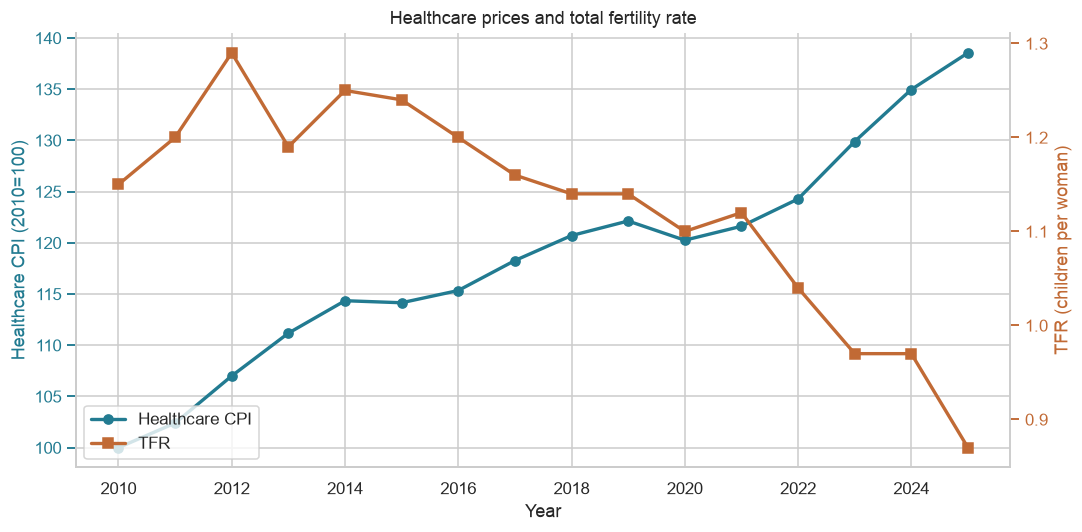

In [7]:
fig, ax = plt.subplots(figsize=(10,5))
other=ax.twinx()
a=ax.plot(df.index,df.cpi_health_2010_100,color='#227b91',marker='o',lw=2.2,label='Healthcare CPI')
b=other.plot(df.index,df.tfr_per_female,color='#c16a35',marker='s',lw=2.2,label='TFR')
ax.set(xlabel='Year',ylabel='Healthcare CPI (2010=100)',title='Healthcare prices and total fertility rate')
other.set_ylabel('TFR (children per woman)',color='#c16a35')
ax.yaxis.label.set_color('#227b91'); ax.tick_params(axis='y',colors='#227b91')
other.tick_params(axis='y',colors='#c16a35'); other.grid(False)
other.spines['right'].set_visible(True)
ax.set_xticks(df.index[::2]); ax.legend(a+b,[x.get_label() for x in a+b],loc='lower left')
show_chart('01_cpi_tfr_comparison')
cpi=df.cpi_health_2010_100.dropna(); tfr=df.tfr_per_female.dropna()


**Finding.** Healthcare CPI rose from 100.00 in 2010 to 138.55 in 2025, while TFR fell from 1.15 to 0.87. These are concurrent long-run patterns(Healthcare CPI is risng and the TFR decreasing).

## Figure 2 — Bar chart: household healthcare spending

**Question:** How much did households spend on healthcare in the observed survey years?

Bar height is monthly spending in nominal SGD. Labels also show its share of household spending. The three bars are separate survey waves, not consecutive annual observations.

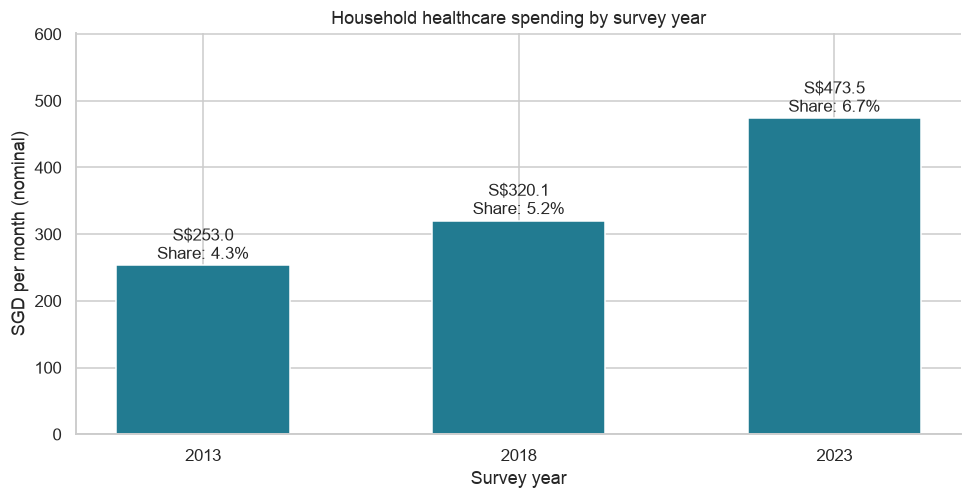

In [8]:
amount='hes_all_households_health_monthly_sgd'
share='hes_all_households_health_share_pct'
waves=df[[amount,share]].dropna()
fig,ax=plt.subplots(figsize=(9,4.7))
bars=ax.bar(waves.index.astype(str),waves[amount],color='#227b91',width=.55)
for bar,(year,row) in zip(bars,waves.iterrows()):
    ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+10,
            f'S${row[amount]:,.1f}\nShare: {row[share]:.1f}%',ha='center',fontsize=11)
ax.set_ylim(0,waves[amount].max()*1.27)
ax.set(title='Household healthcare spending by survey year',xlabel='Survey year',ylabel='SGD per month (nominal)')
show_chart('02_household_healthcare_spending')
growth=(waves[amount].iloc[-1]/waves[amount].iloc[0]-1)*100
pp=waves[share].iloc[-1]-waves[share].iloc[0]


**Finding.** Monthly household healthcare spending increased from 253.0 in 2013 to 473.5 in 2023, an increase of 87.2%. Its share of household spending rose from 4.3% to 6.7%, or 2.4 percentage points. 

## Figure 3 — Scatter plots: healthcare CPI–TFR correlation

Each point is one year, coloured by year. The left panel compares original levels; the right compares **annual absolute changes**, calculated only for adjacent calendar years. The dashed line is a descriptive linear fit, and Pearson r measures linear association (−1 to +1). The second panel checks whether the level association persists when looking at changes. 

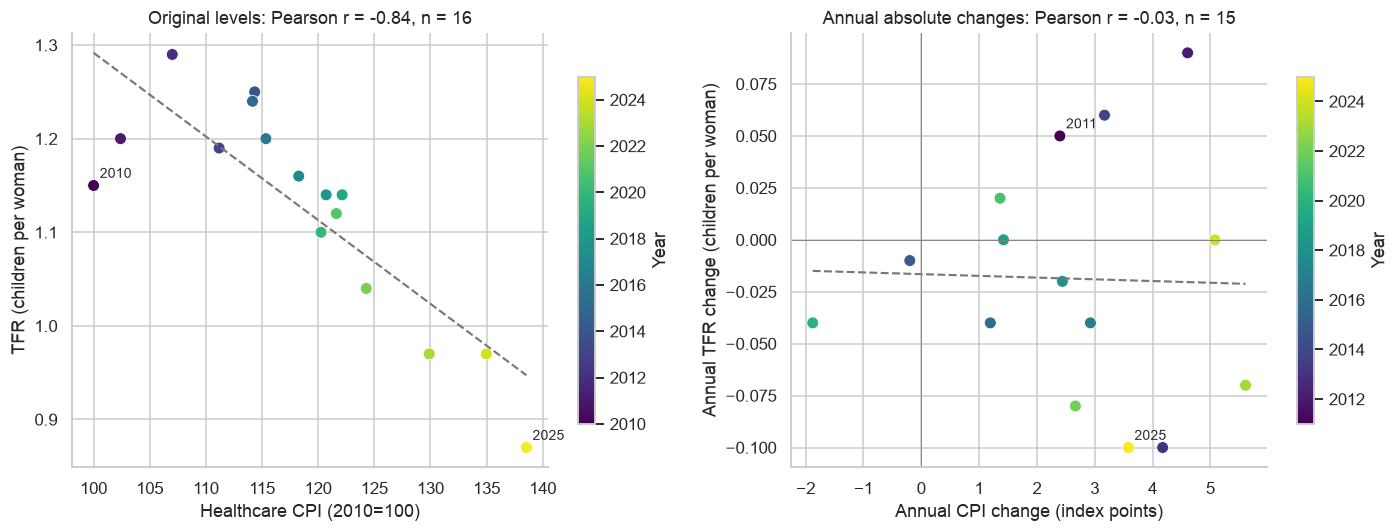

In [9]:
pair=df[['cpi_health_2010_100','tfr_per_female']].dropna()
changes=df[['cpi_health_2010_100','tfr_per_female']].diff().dropna()
fig,axes=plt.subplots(1,2,figsize=(13,5))
correlations=[]
for ax,table,title,xlabel,ylabel in [
    (axes[0],pair,'Original levels','Healthcare CPI (2010=100)','TFR (children per woman)'),
    (axes[1],changes,'Annual absolute changes','Annual CPI change (index points)','Annual TFR change (children per woman)')]:
    x=table.iloc[:,0]; y=table.iloc[:,1]
    r=x.corr(y) if len(table)>=3 and x.nunique()>1 and y.nunique()>1 else np.nan
    dots=ax.scatter(x,y,c=table.index,cmap='viridis',s=60,edgecolor='white',linewidth=.5)
    if len(table)>=3 and x.nunique()>1:
        slope,intercept=np.polyfit(x,y,1)
        xx=np.linspace(x.min(),x.max(),100)
        ax.plot(xx,slope*xx+intercept,color='#777777',ls='--',lw=1.4)
    for year in [table.index.min(),table.index.max()]:
        ax.annotate(str(year),(table.loc[year].iloc[0],table.loc[year].iloc[1]),xytext=(4,5),textcoords='offset points',fontsize=9)
    ax.set(title=f'{title}: Pearson r = {r:.2f}, n = {len(table)}',xlabel=xlabel,ylabel=ylabel)
    fig.colorbar(dots,ax=ax,label='Year',shrink=.8)
    correlations.append({'comparison':title,'n':len(table),'pearson_r':r})
axes[1].axhline(0,color='grey',lw=.6); axes[1].axvline(0,color='grey',lw=.6)
show_chart('03_cpi_tfr_scatter')
pd.DataFrame(correlations).to_csv(OUT/'cpi_tfr_correlations.csv',index=False)


**Finding.** Healthcare CPI and TFR have a Pearson correlation of approximately −0.84 in levels (16 years), compared with −0.03 in annual absolute changes (15 pairs). The contrast suggests that the level association is sensitive to shared time trends. 

## Figure 4 — Box plot: annual healthcare price changes

**Question:** How did annual price changes vary across selected healthcare categories?

YoY = 100 × (this year's index / previous year's index − 1). Only adjacent observed calendar years are used. Each dot represents one year, the box covers the middle 50% of observations, and the line inside is the median. Whiskers follow the 1.5×IQR rule; all observations are shown as dots.

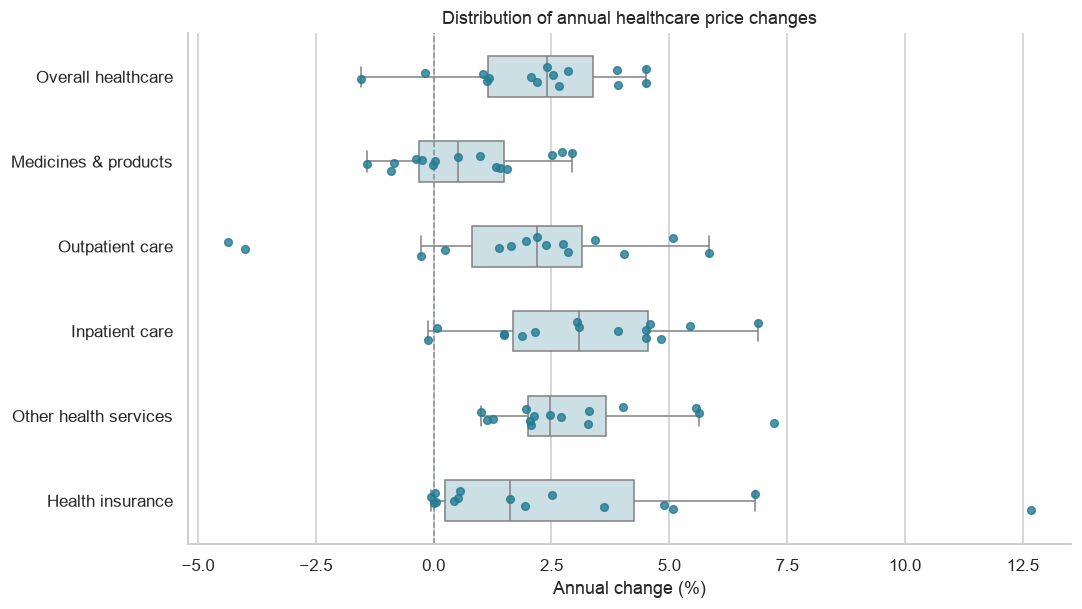

In [10]:
price_labels={'cpi_health_2010_100':'Overall healthcare',
              'cpi_medicines_health_products_2010_100':'Medicines & products',
              'cpi_outpatient_care_2010_100':'Outpatient care',
              'cpi_inpatient_care_2010_100':'Inpatient care',
              'cpi_other_health_services_2010_100':'Other health services',
              'cpi_health_insurance_2010_100':'Health insurance'}
prices=df[list(price_labels)]
yoy=prices.div(prices.shift(1).replace(0,np.nan)).sub(1).mul(100)
plot_data=yoy.rename(columns=price_labels).melt(var_name='Category',value_name='Annual change (%)').dropna()
fig,ax=plt.subplots(figsize=(10,5.7))
sns.boxplot(data=plot_data,x='Annual change (%)',y='Category',color='#c7e1e8',showfliers=False,width=.48,ax=ax)
# Deterministic dot positions: one dot per observed annual change.
for i,(c,name) in enumerate(price_labels.items()):
    vals=yoy[c].dropna()
    ax.scatter(vals,np.full(len(vals),i)+np.linspace(-.11,.11,len(vals)),color='#227b91',s=25,alpha=.8,zorder=3)
ax.axvline(0,color='#858e96',linestyle='--',linewidth=1)
ax.set_title('Distribution of annual healthcare price changes')
ax.set_ylabel(''); show_chart('04_annual_price_change_distribution')
overall=yoy['cpi_health_2010_100'].dropna()
insurance=yoy['cpi_health_insurance_2010_100'].dropna()
yoy.to_csv(OUT/'annual_price_changes.csv',index_label='year')
assert yoy.iloc[0].isna().all()
assert not (prices.shift(1).isna() & yoy.notna()).any().any()


**Finding.** Medicines and health products generally show smaller annual price changes than inpatient care. Outpatient care includes years of price declines. Health insurance has a wide range of annual changes, including a 12.68% increase in 2025. 

## Figure 5 — Area charts: government healthcare expenditure

Three separate panels show **total expenditure**, **per-capita expenditure** and **expenditure as a share of GDP**. These describe scale, spending per person and spending relative to the economy. Each panel uses a zero baseline and its own unit; shaded areas are not cumulative totals or additive components.

All three supplied series end in 2023. No 2024–2025 values are imputed. 

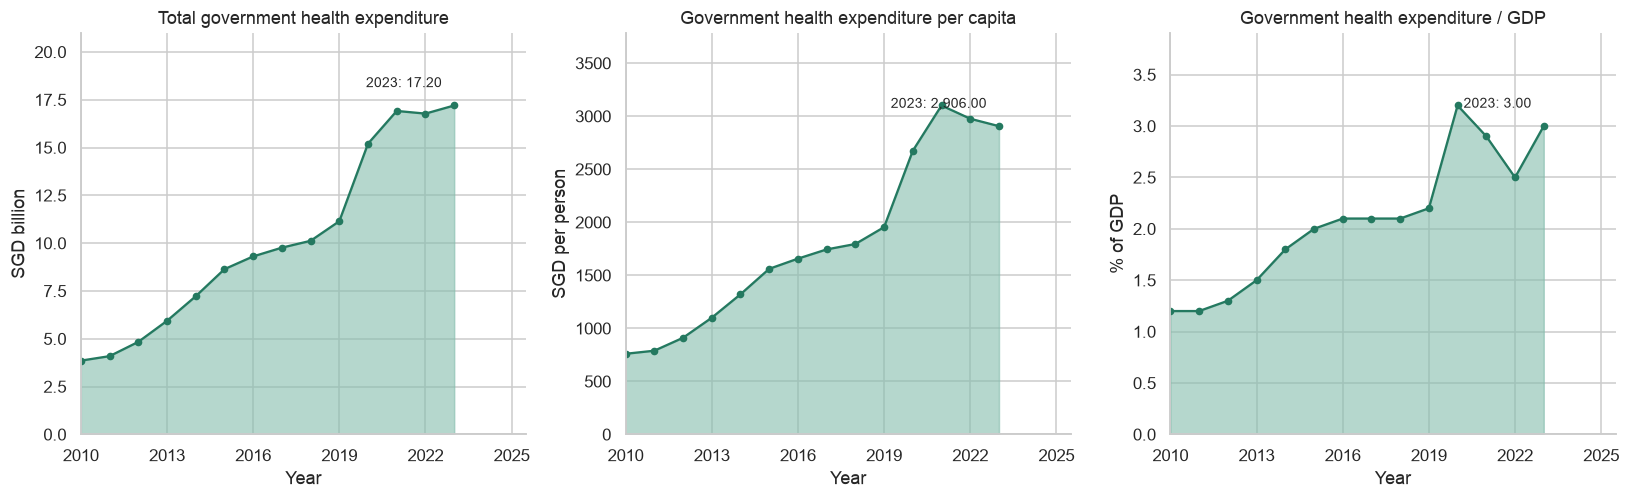

,metric,unit,first_year,first_value,latest_year,latest_value
0,gov_health_expenditure_sgd_million,SGD billion,2010,3.8567,2023,17.199
1,gov_health_per_capita_sgd,SGD per person,2010,760.0000,2023,2906.000
2,gov_health_expenditure_gdp_pct,% of GDP,2010,1.2000,2023,3.000


Completed: five figures, with code and interpretations in this notebook.


In [11]:
government={
    'gov_health_expenditure_sgd_million':('Total government health expenditure','SGD billion',1000),
    'gov_health_per_capita_sgd':('Government health expenditure per capita','SGD per person',1),
    'gov_health_expenditure_gdp_pct':('Government health expenditure / GDP','% of GDP',1)
}
fig,axes=plt.subplots(1,3,figsize=(15,4.7))
gov_rows=[]
for ax,(c,(title,unit,scale)) in zip(axes,government.items()):
    series=df[c]/scale; valid=series.dropna()
    ax.fill_between(series.index,series.to_numpy(),0,color='#85bdad',alpha=.6)
    ax.plot(series.index,series,color='#247960',marker='o',ms=4)
    ax.set(title=title,ylabel=unit,xlabel='Year',ylim=(0,valid.max()*1.22))
    ax.set_xticks(df.index[::3]); ax.set_xlim(df.index.min(),df.index.max()+.5)
    yr=valid.index[-1]
    ax.annotate(f'{yr}: {valid.iloc[-1]:,.2f}',(yr,valid.iloc[-1]),xytext=(-8,12),textcoords='offset points',ha='right',fontsize=9)
    gov_rows.append({'metric':c,'unit':unit,'first_year':valid.index[0],'first_value':valid.iloc[0],
                     'latest_year':yr,'latest_value':valid.iloc[-1]})
show_chart('05_government_healthcare_expenditure')
gov_summary=pd.DataFrame(gov_rows)
display(gov_summary)
gov_summary.to_csv(OUT/'government_healthcare_summary.csv',index=False)
total=df.gov_health_expenditure_sgd_million.dropna()
percap=df.gov_health_per_capita_sgd.dropna()
share=df.gov_health_expenditure_gdp_pct.dropna()
assert len(list(government))==3
print('Completed: five figures, with code and interpretations in this notebook.')


**Finding** Government healthcare expenditure increased from 3.86 billion in 2010 to 17.20 billion in 2023. Per-capita expenditure increased from 760 to 2,906, while spending as a share of GDP rose from 1.2% to 3.0%. 

## Summary

Healthcare prices, household spending and government expenditure increased over their observed periods. TFR generally declined. The CPI–TFR correlation is strongly negative in levels but close to zero in annual changes, so the level association should not be treated as evidence of causation.

There are at most 16 annual observations, three household survey waves and different end years across indicators. Monetary values are nominal. Government expenditure about healthcare cannot cover the rising healthcare costs, and the expenditure willing of the government is not too "strong".

# Part 2 · Housing

Presenter: Angelica Wu

Converted from `housing_fertility_analysis.py` and `Final_Report.md`. The original `BirthRate.csv`, `HDB_Resale_Price.csv` and `Private_Housing_Annual.csv` inputs are now read from `Fertility_Combined_Data.csv`; the cleaned tables and charts are identical.

Housing costs may influence family formation by affecting resources available for raising children. Higher housing expenditure could encourage couples to postpone parenthood, while existing homeowners may benefit from rising property values. This analysis examines housing price trends and fertility from 2000 to 2025, with a separate 2020 Census snapshot of households with children.

### Data notes

Inputs: original uploaded BirthRate.csv and HDB_Resale_Price.csv; annual private housing indices from the previously verified URA annual comparison. Private_Housing_Annual.csv contains annual averages, not individual transactions.

Sources:
- Private housing: https://data.gov.sg/datasets/d_da00b36ca8c831322fa0bb2a3378a476/view
- Household comparison: https://data.gov.sg/datasets/d_7363ba6451d9a8e25d8c081b553b6c6c/view (Census 2020, CT/17486, revised June 2026)
- Fertility: uploaded SingStat BirthRate.csv, total fertility and age-specific fertility series.
- HDB: uploaded SingStat HDB_Resale_Price.csv, quarterly HDB Resale Price Index.

Household counts are a documented 2020 snapshot entered in the script: HDB with/without children 526014/181701; condos 120714/36881; landed 43865/10970. Private combines condos and landed. Percentages use married-couple households only. These are not annual births or fertility rates. Children may be adults, and children living elsewhere are not counted in that household category.

Outputs: five PNG charts, annual cleaned HDB data, merged 2000–2025 data, household data, and age-specific correlations.

HDB annual averages require four distinct quarters. Total fertility is read directly, not calculated from rounded age-specific rates. All housing indices are rebased to 2000 = 100. Pearson correlations use annual levels and may reflect shared time trends. They are not causal estimates. No income adjustment or age adjustment is applied to household comparisons.

In [12]:
# Housing outputs (charts and cleaned tables) are saved under sections/housing/outputs.
(ROOT / 'sections' / 'housing').mkdir(parents=True, exist_ok=True)
os.chdir(ROOT / 'sections' / 'housing')

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from IPython.display import Image, display

matplotlib.rcdefaults()   # start from matplotlib defaults, as the original stand-alone script did
BASE = Path.cwd()
OUT = BASE / 'outputs'
OUT.mkdir(exist_ok=True)
START, END = 2000, 2025
AGES = [f'{a} - {a+4} Years' for a in range(15, 50, 5)]
LABELS = [f'{a}–{a+4}' for a in range(15, 50, 5)]
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': 'white'})


def save(fig, filename, note):
    fig.text(.08, .025, note, fontsize=9, color='#58677c')
    fig.savefig(OUT / filename, dpi=220, bbox_inches='tight')
    plt.close(fig)

In [13]:
# 1. Convert HDB quarterly data to annual averages; require four distinct quarters.
# Combined notebook: quarterly HDB index read from Fertility_Combined_Data.csv (4Q to 1Q, as in the SingStat file).
hdb_quarters = load_section('housing_hdb_quarterly')
q = hdb_quarters.melt(id_vars='Year', var_name='Quarter', value_name='Index')
q = q.dropna().astype({'Year': int, 'Quarter': int})
if q.duplicated(['Year', 'Quarter']).any():
    raise ValueError('Duplicate HDB quarterly observations.')
complete = q.groupby('Year')['Quarter'].nunique()
hdb = q[q.Year.isin(complete[complete.eq(4)].index)].groupby('Year')['Index'].mean()
hdb = hdb.rename('HDB_Resale_Price_Index').reset_index()

# 2. Read total fertility and age-specific fertility as distinct measures.
# Combined notebook: fertility and URA private indices read from Fertility_Combined_Data.csv.
fertility = load_section('housing_fertility')
private = load_section('housing_private')
df = hdb.merge(fertility, on='Year', validate='one_to_one').merge(
    private, on='Year', validate='one_to_one')
df = df[df.Year.between(START, END)].sort_values('Year').reset_index(drop=True)
if df.Year.tolist() != list(range(START, END+1)) or df.isna().any().any():
    raise ValueError('Expected complete annual data for 2000–2025.')
price_cols = ['HDB_Resale_Price_Index', 'Private_Landed_Index', 'Private_Non_Landed_Index']
for col in price_cols:
    df[col + '_2000_100'] = df[col] / df.loc[0, col] * 100
hdb[hdb.Year.between(START, END)].to_csv(OUT/'HDB_Annual_Cleaned.csv', index=False)
df.to_csv(OUT/'Housing_Fertility_Merged_2000_2025.csv', index=False)

## Figure 1: Housing Price Indices and Total Fertility Rate in Singapore, 2000–2025

Quarterly housing indices are averaged by year, then rebased to 2000 = 100. Housing indices use the left axis; total fertility uses the right axis.

HDB resale prices increased by 159.2%, compared with 145.5% for private landed homes and 112.1% for private condos and apartments. Total fertility declined from 1.60 to 0.87 children per woman, approximately 45.6%. These opposing long-term trends support investigating housing costs as a potential factor associated with family formation, but do not establish causation. Price indices measure price growth rather than dollar prices or affordability. Income, subsidies, financing costs and family preferences also matter. Line intersections have no numerical meaning because the axes use different units.

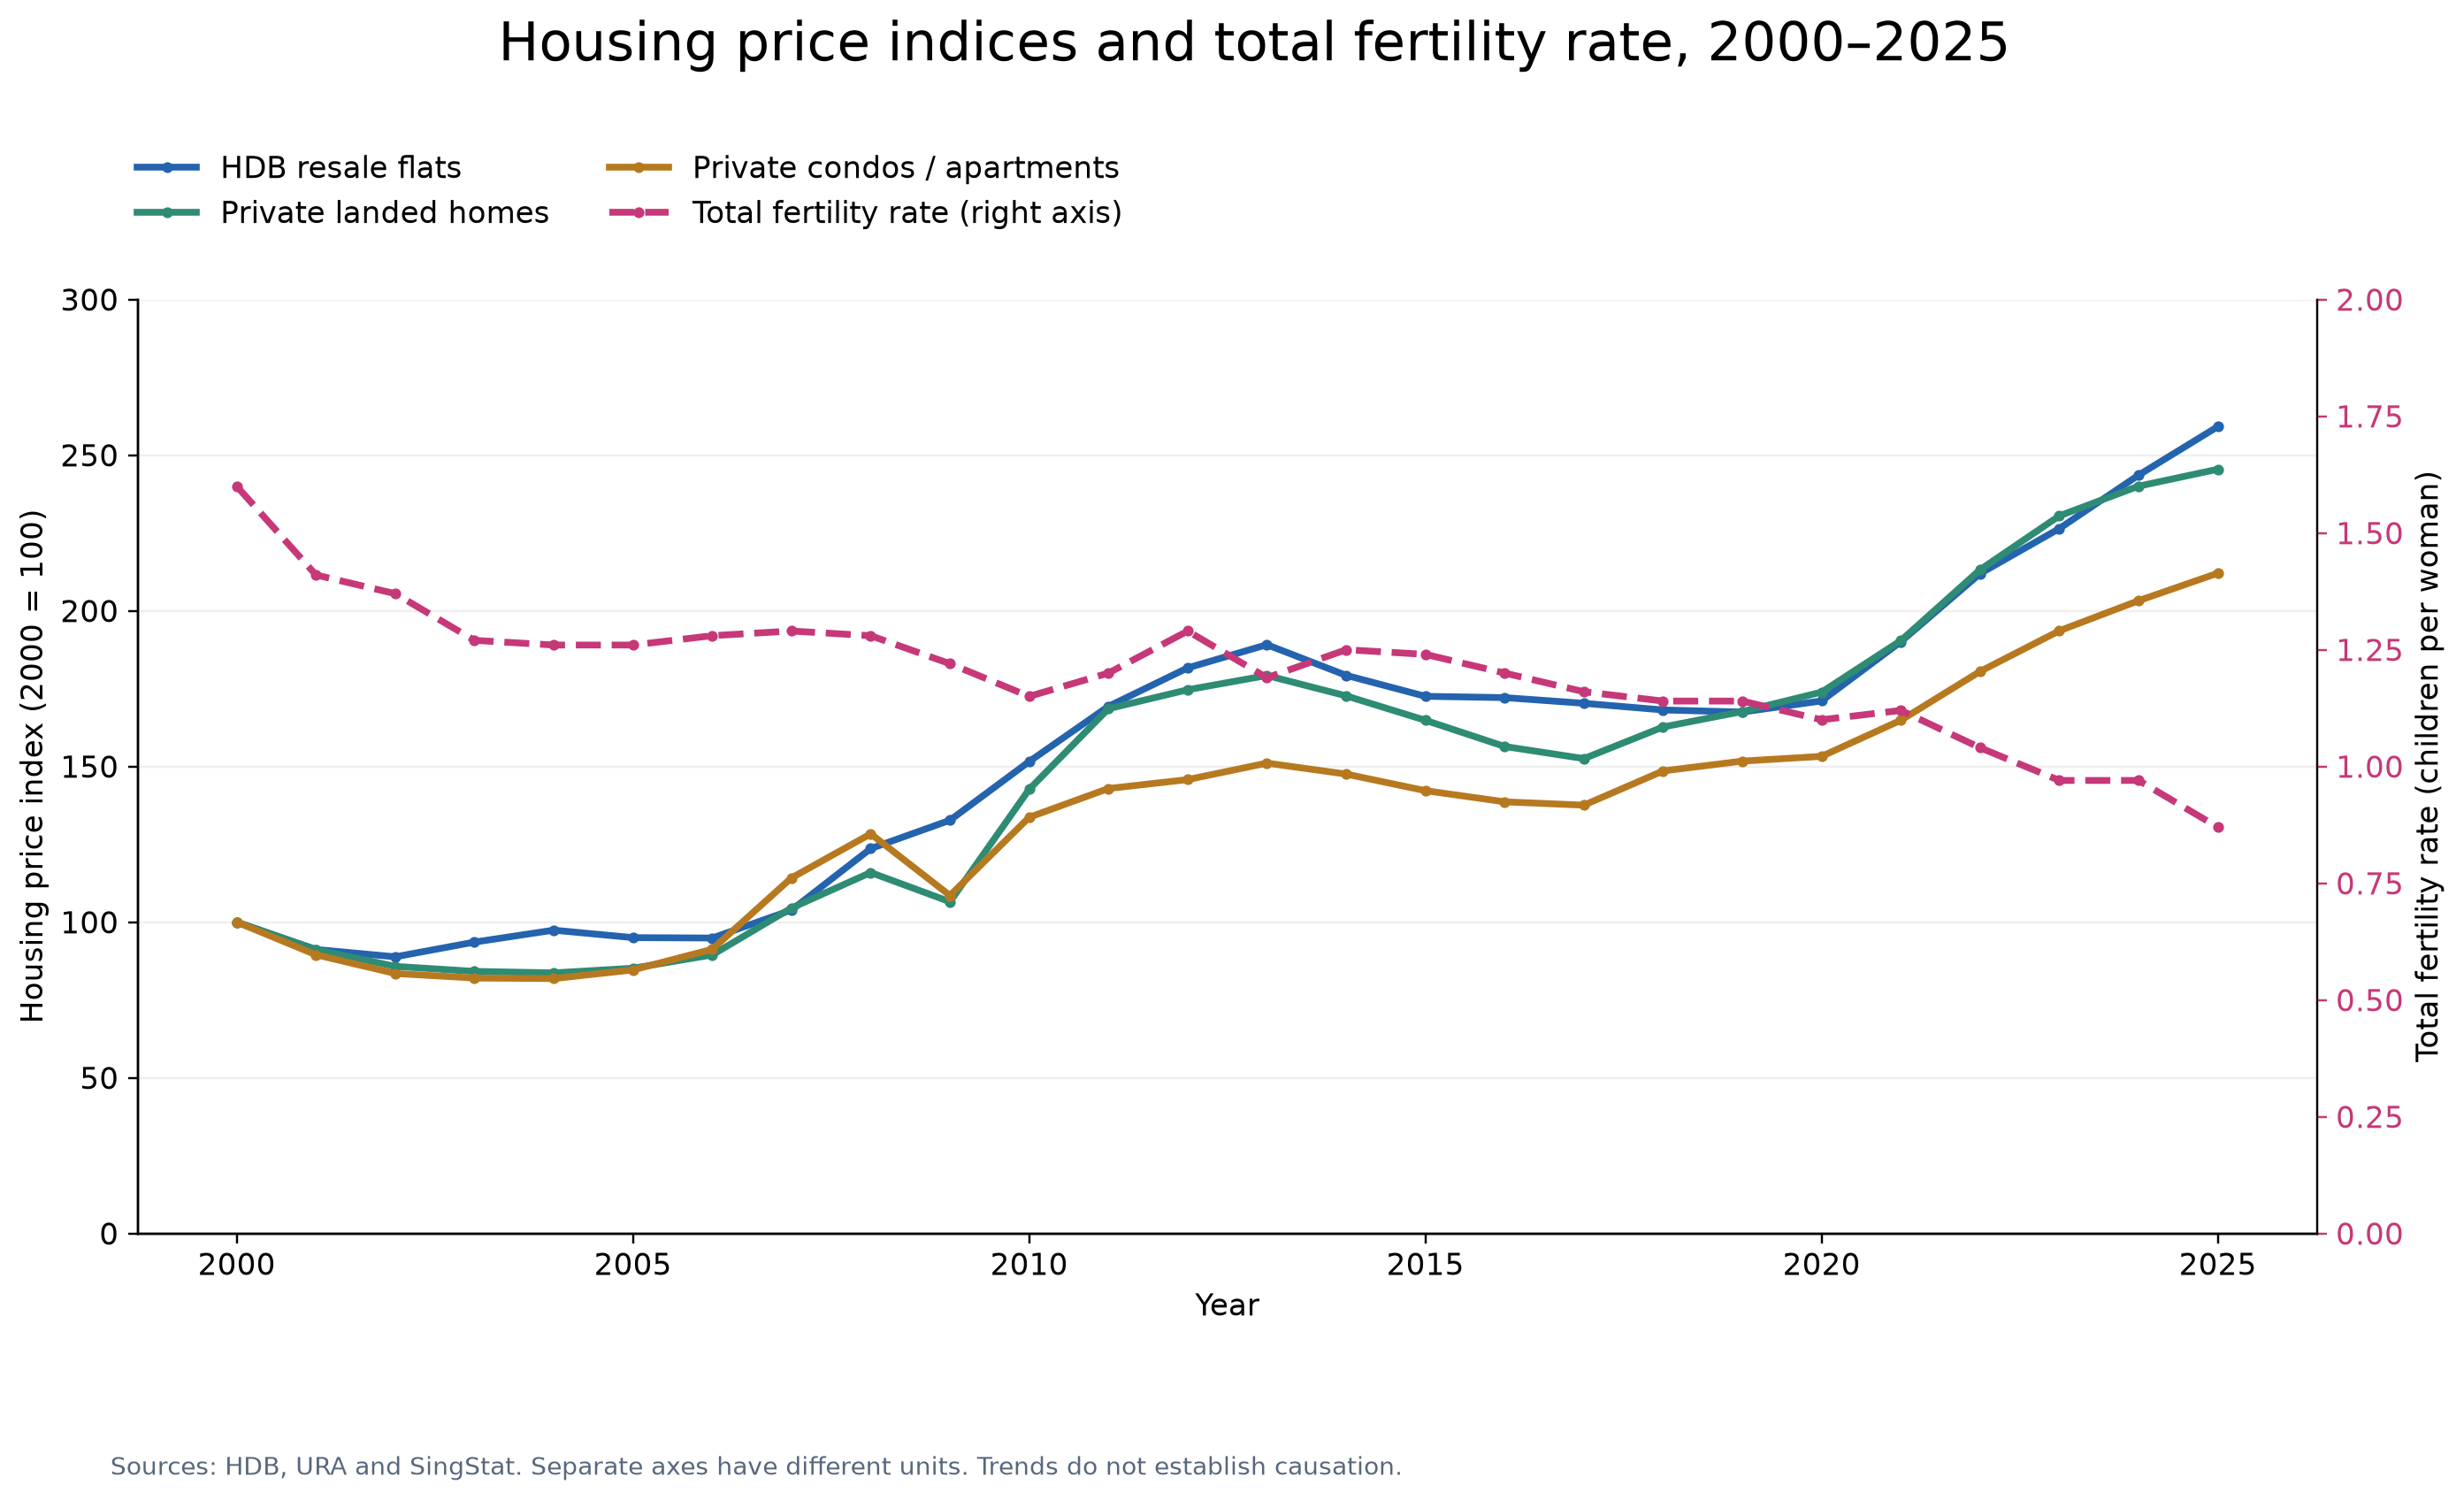

In [14]:
# 3. Combined housing-price and fertility chart.
fig, ax = plt.subplots(figsize=(14, 8))
fig.subplots_adjust(left=.09, right=.89, top=.78, bottom=.18)
fig.suptitle('Housing price indices and total fertility rate, 2000–2025', fontsize=20, y=.96)
lines = []
for col, label, color in zip(price_cols,
        ['HDB resale flats', 'Private landed homes', 'Private condos / apartments'],
        ['#2463ae', '#2e8b74', '#b77920']):
    lines += ax.plot(df.Year, df[col+'_2000_100'], label=label, color=color,
                     linewidth=2.5, marker='o', markersize=3)
ax.set(xlabel='Year', ylabel='Housing price index (2000 = 100)', ylim=(0,300))
ax.grid(axis='y', alpha=.2)
right = ax.twinx()
right.spines['right'].set_visible(True)
lines += right.plot(df.Year, df.Total_Fertility_Rate, '--o', color='#c63878',
                    linewidth=2.5, markersize=3, label='Total fertility rate (right axis)')
right.set(ylim=(0,2), ylabel='Total fertility rate (children per woman)')
right.tick_params(axis='y', colors='#c63878')
fig.legend(lines, [line.get_label() for line in lines], loc='upper left',
           bbox_to_anchor=(.08,.89), ncol=2, frameon=False)
save(fig, '01_combined_housing_fertility.png',
     'Sources: HDB, URA and SingStat. Separate axes have different units. Trends do not establish causation.')
display(Image(filename=str(OUT / '01_combined_housing_fertility.png')))

## Figure 2: Married-Couple Households with Children by Housing Type, Singapore, 2020

In 2020, 526,014 married-couple households with children lived in HDB flats, compared with 164,579 in private housing. Among married-couple households in each housing category, 74.3% in HDB flats and 77.5% in private housing had children living in the household. Private housing combines condominiums/other apartments and landed properties.

HDB has more such households in absolute terms, while private housing has a slightly higher within-category share. The figures provide context for family formation rather than showing higher fertility in either group. Children may be adults, and households without children living with them may have children elsewhere. Age, income and other differences are not controlled. This snapshot does not measure births in 2020 or total fertility rates.

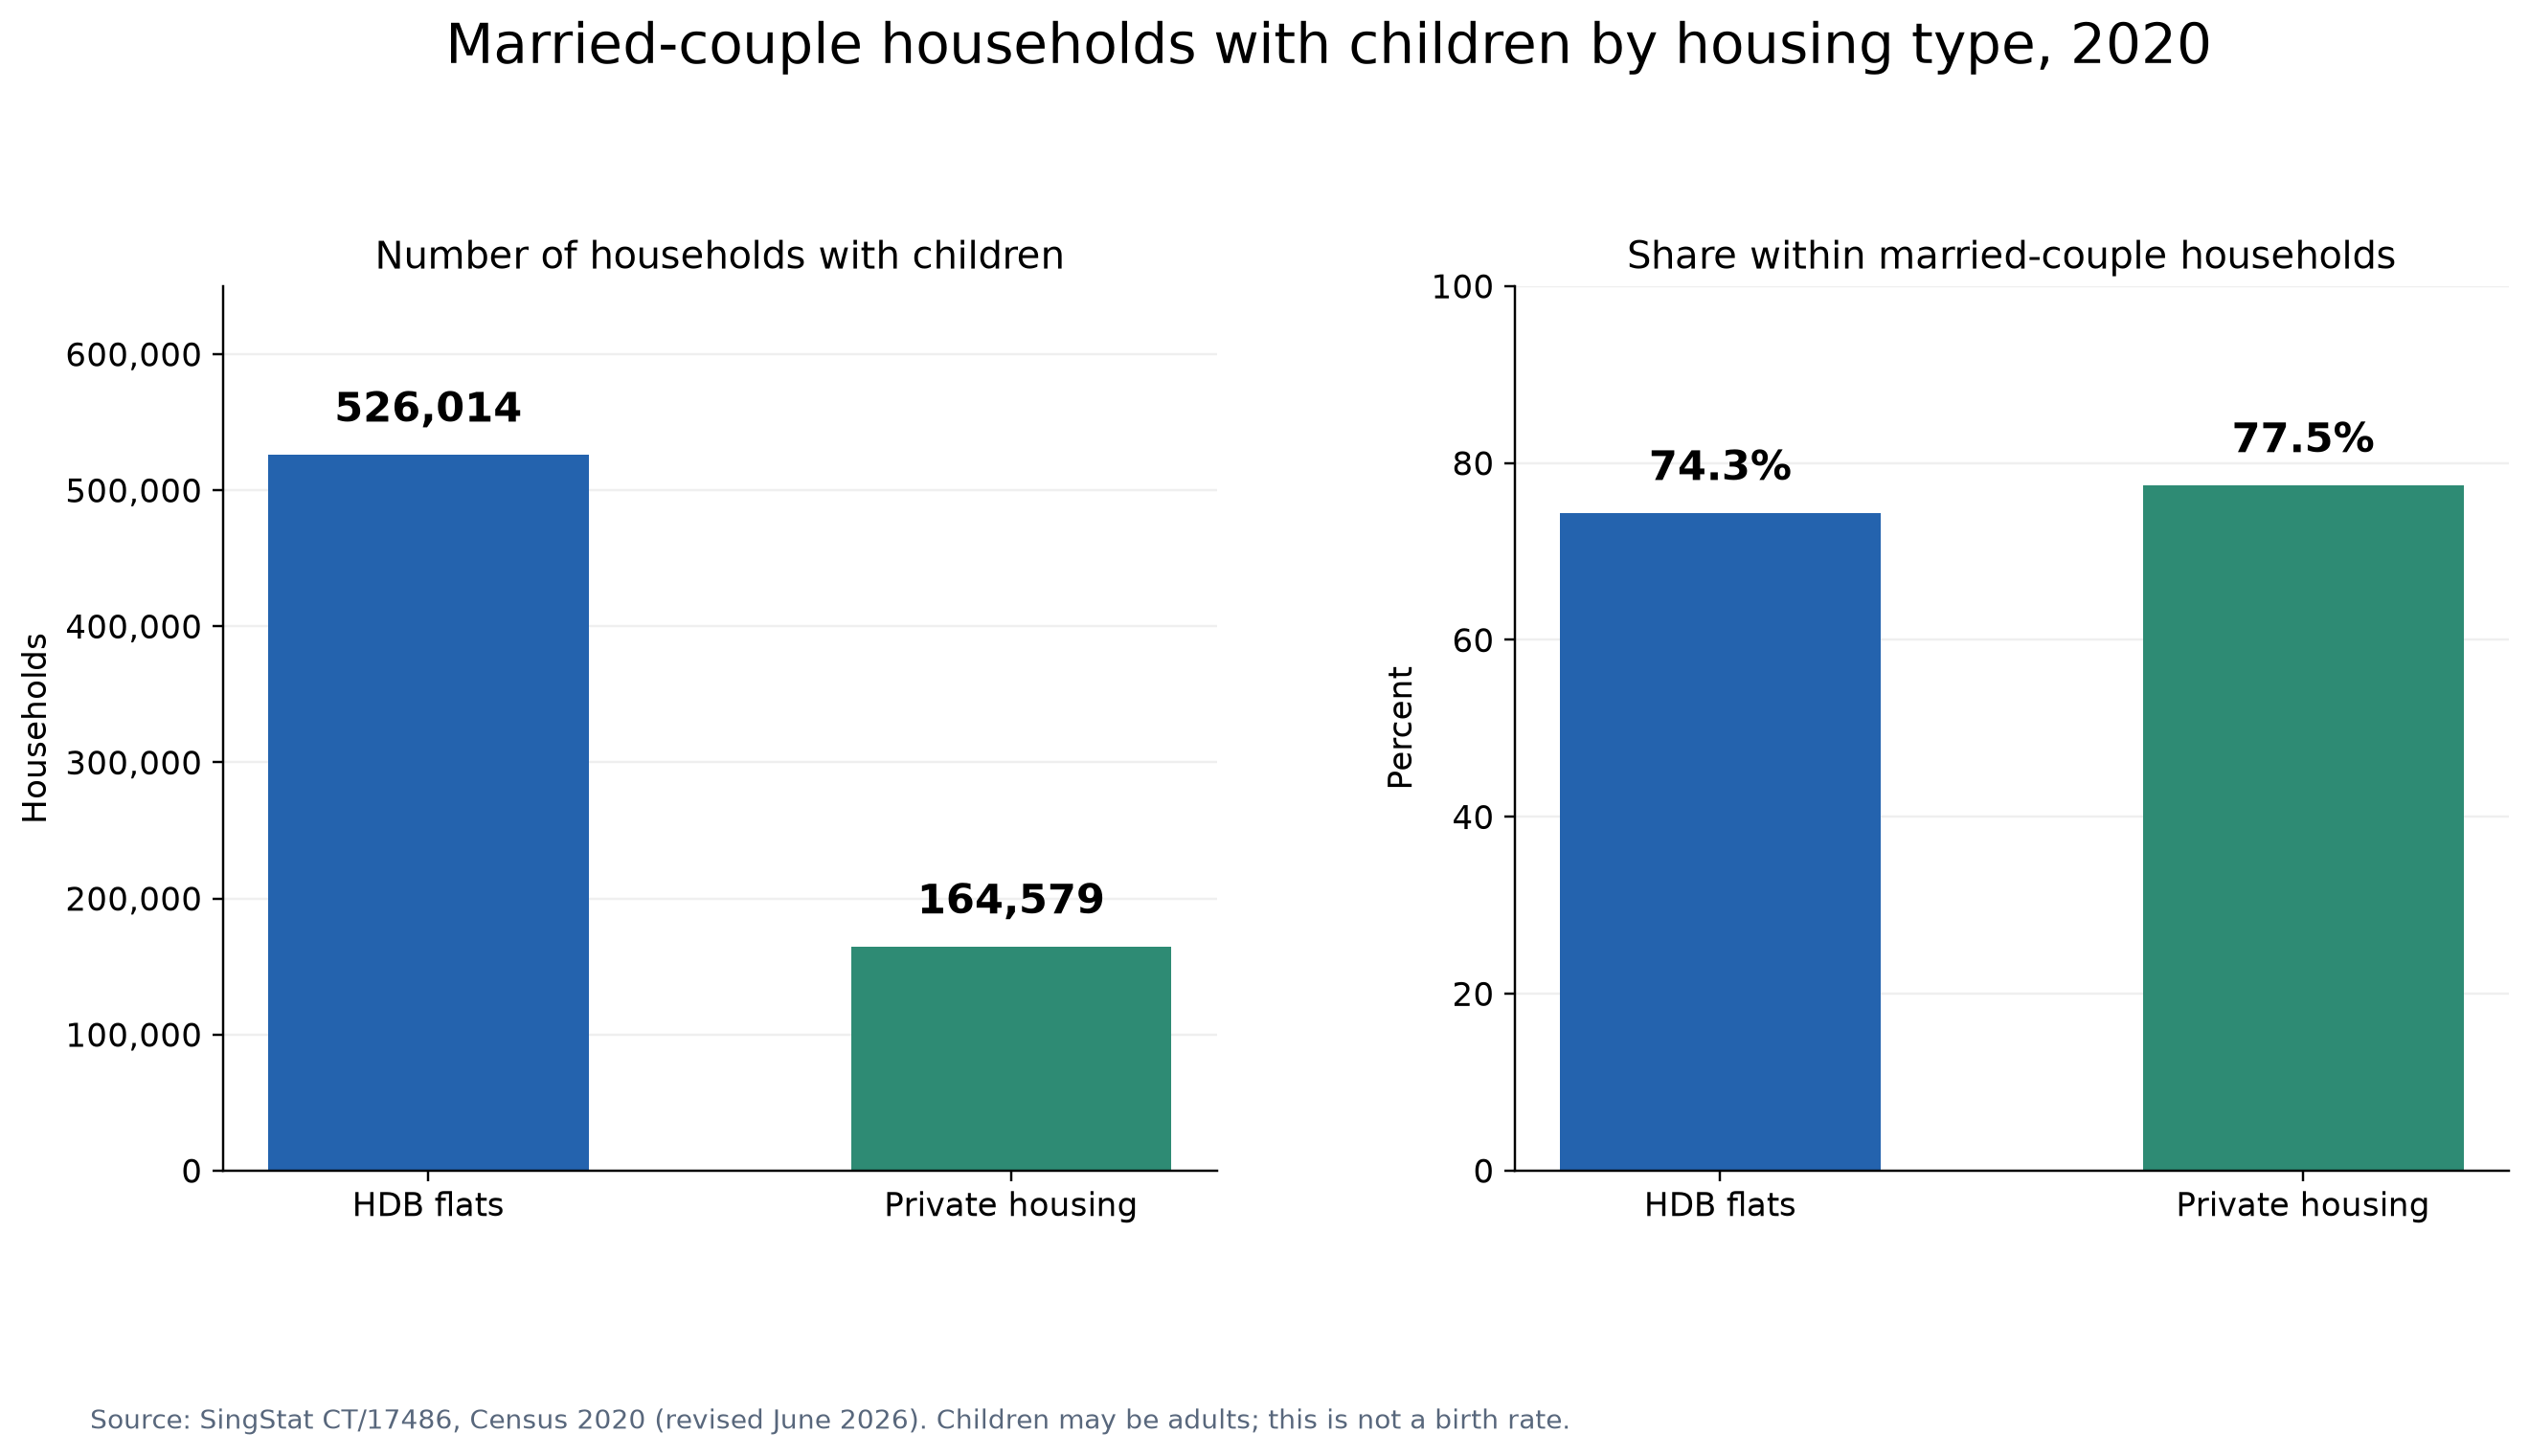

In [15]:
# 4. Census household counts and normalized percentages; not births or TFR.
households = pd.DataFrame({'Housing_Type':['HDB flats','Private housing'],
    'With_Children':[526014,120714+43865],
    'Without_Children':[181701,36881+10970]})
households['Share_With_Children_Percent'] = 100*households.With_Children / (
    households.With_Children+households.Without_Children)
households.to_csv(OUT/'Census_2020_Married_Couple_Households.csv', index=False)
fig, axes = plt.subplots(1,2,figsize=(14,7))
fig.subplots_adjust(bottom=.2, top=.8, wspace=.3)
fig.suptitle('Married-couple households with children by housing type, 2020',fontsize=19)
for ax, column, title, ylabel, limit in zip(axes,
    ['With_Children','Share_With_Children_Percent'],
    ['Number of households with children','Share within married-couple households'],
    ['Households','Percent'], [650000,100]):
    bars=ax.bar(households.Housing_Type, households[column],color=['#2463ae','#2e8b74'],width=.55)
    ax.set(title=title,ylabel=ylabel,ylim=(0,limit));ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True)
    labels=[f'{v:,.0f}' if column=='With_Children' else f'{v:.1f}%' for v in households[column]]
    ax.bar_label(bars,labels=labels,padding=8,fontsize=14,weight='bold')
axes[0].yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
save(fig,'02_households_with_children.png',
     'Source: SingStat CT/17486, Census 2020 (revised June 2026). Children may be adults; this is not a birth rate.')
display(Image(filename=str(OUT / '02_households_with_children.png')))

## Figures 3 and 4: Age-Specific Fertility Rates, 2000–2025 and 2000 versus 2025

Age-specific fertility rates are births per 1,000 women in each age group. Rates fell across the groups below age 35. For women aged 25–29, the rate declined from 110.1 to 38.1; for those aged 30–34, it declined from 107.9 to 69.7. Rates increased from 43.3 to 46.0 among women aged 35–39 and from 7.6 to 9.5 among women aged 40–44. These patterns are consistent with childbearing shifting towards older ages. They do not show that housing prices caused the shift, or that later childbearing fully compensated for lower fertility at younger ages.

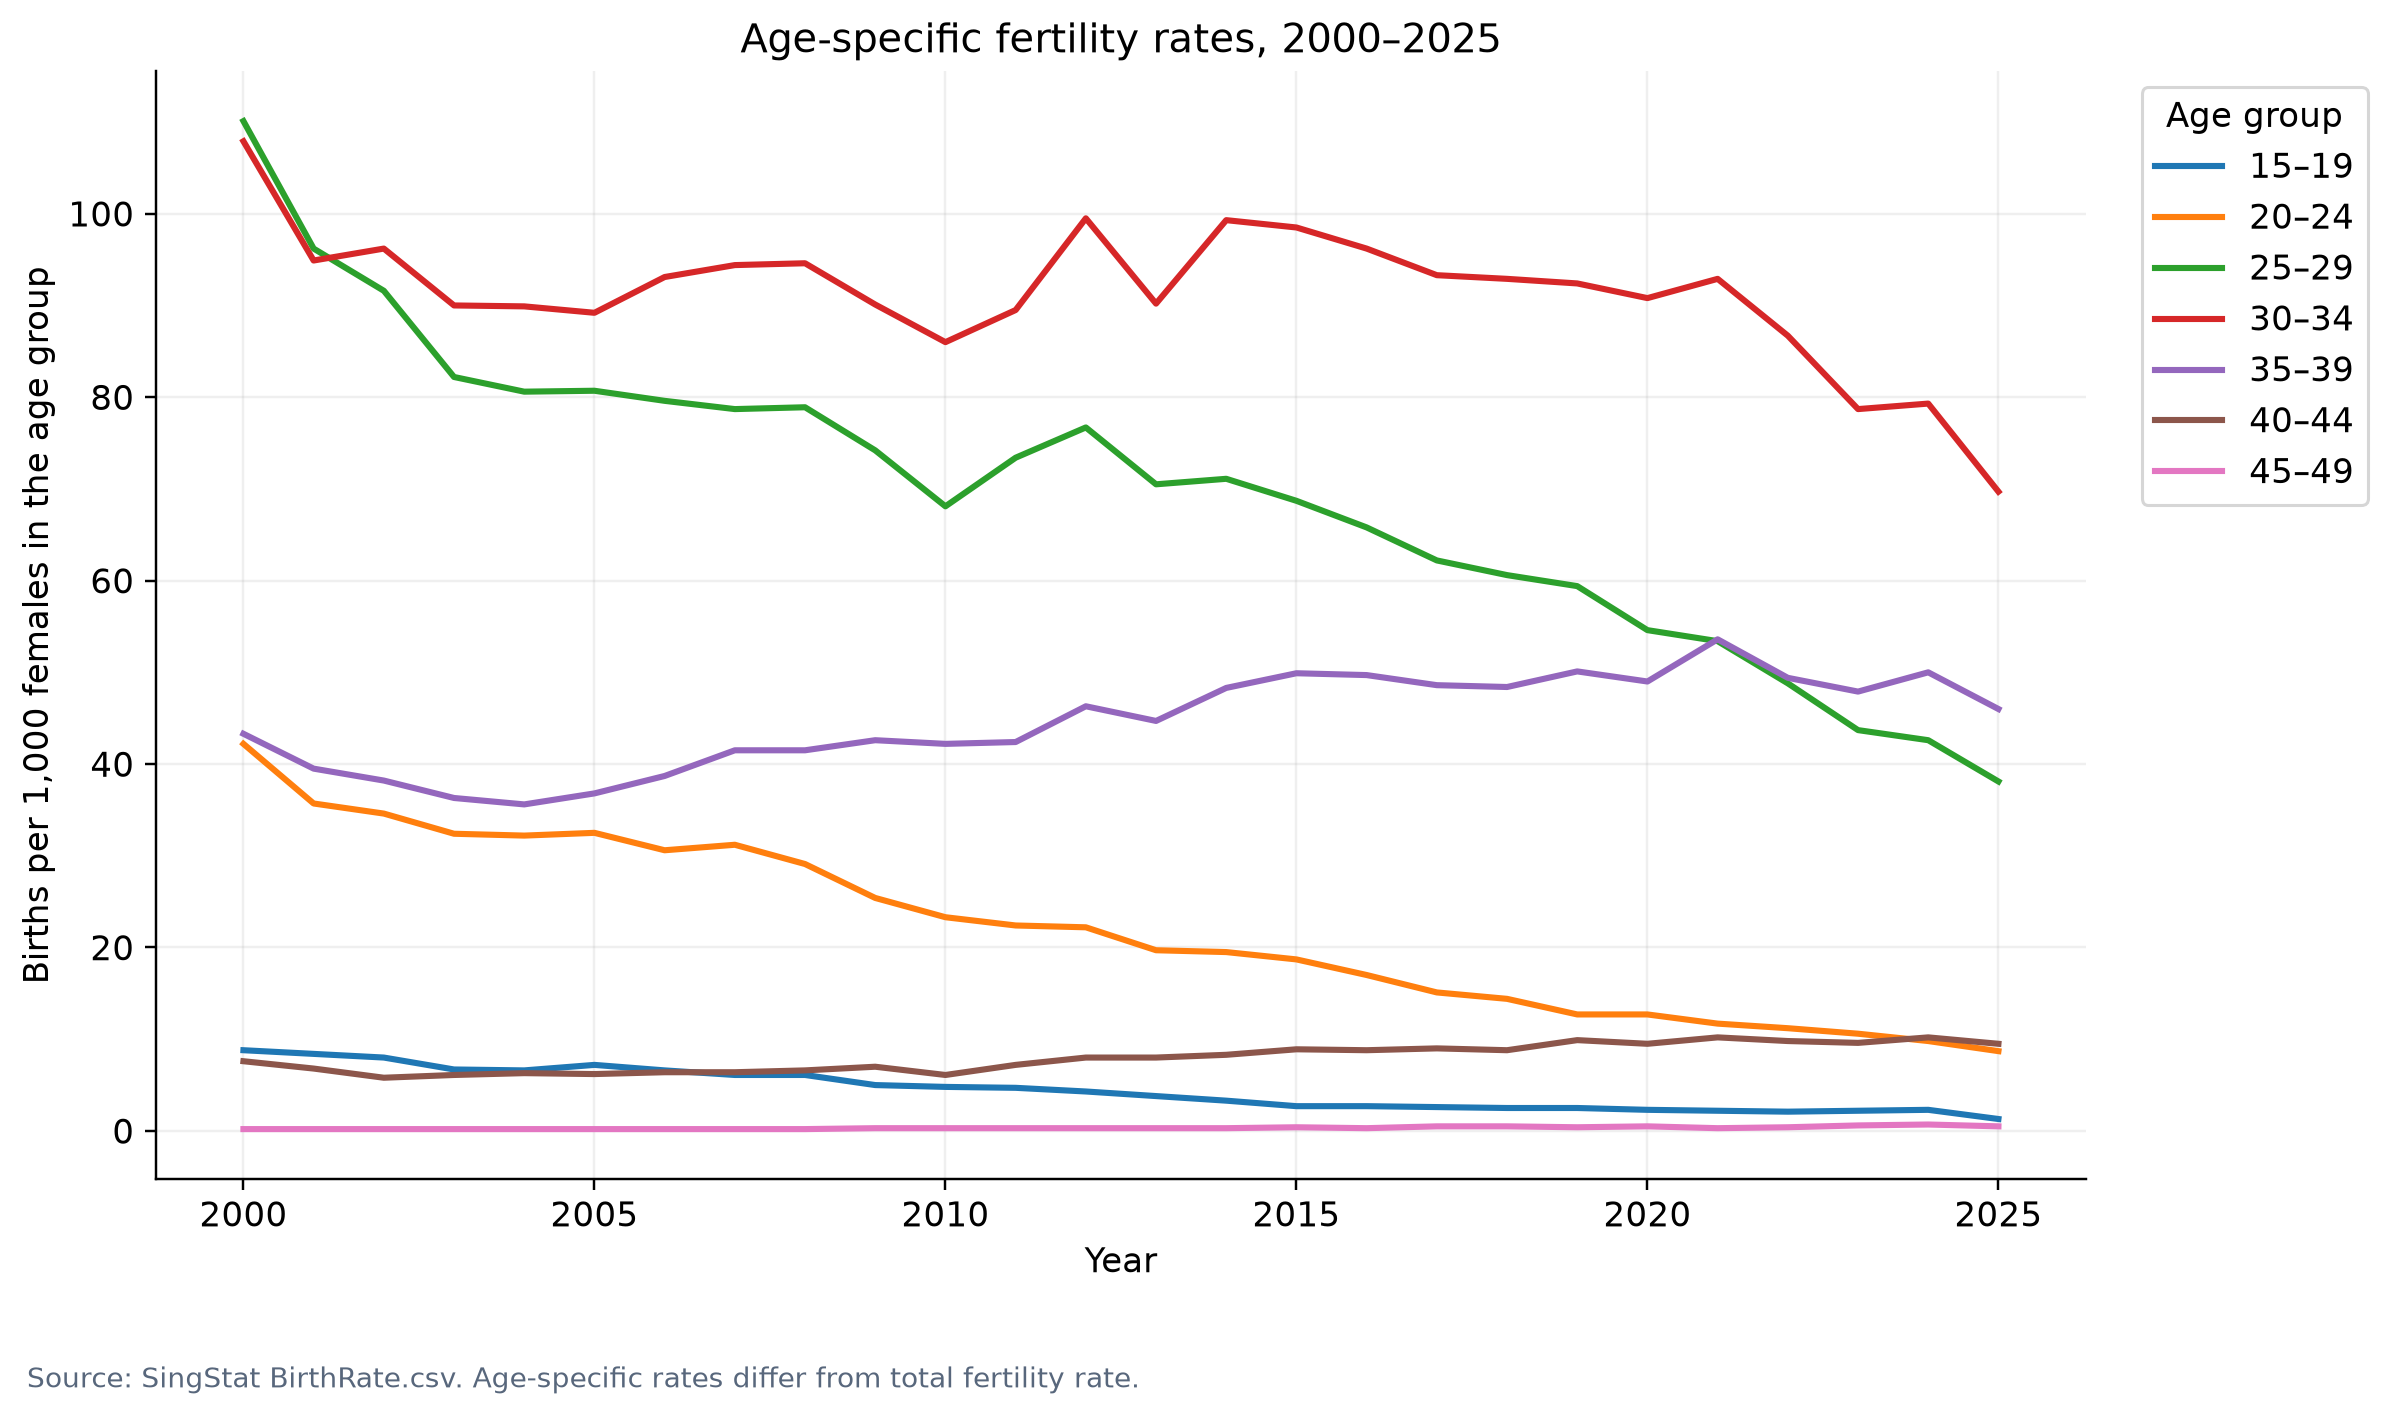

In [16]:
# 5. Age-specific fertility line and endpoint bar charts.
fig,ax=plt.subplots(figsize=(13,7));fig.subplots_adjust(bottom=.16,right=.8)
for age,label in zip(AGES,LABELS):ax.plot(df.Year,df[age],label=label,linewidth=2)
ax.set(title='Age-specific fertility rates, 2000–2025',xlabel='Year',ylabel='Births per 1,000 females in the age group')
ax.legend(title='Age group',bbox_to_anchor=(1.02,1),loc='upper left');ax.grid(alpha=.2)
save(fig,'03_age_fertility_lines.png','Source: SingStat BirthRate.csv. Age-specific rates differ from total fertility rate.')
display(Image(filename=str(OUT / '03_age_fertility_lines.png')))

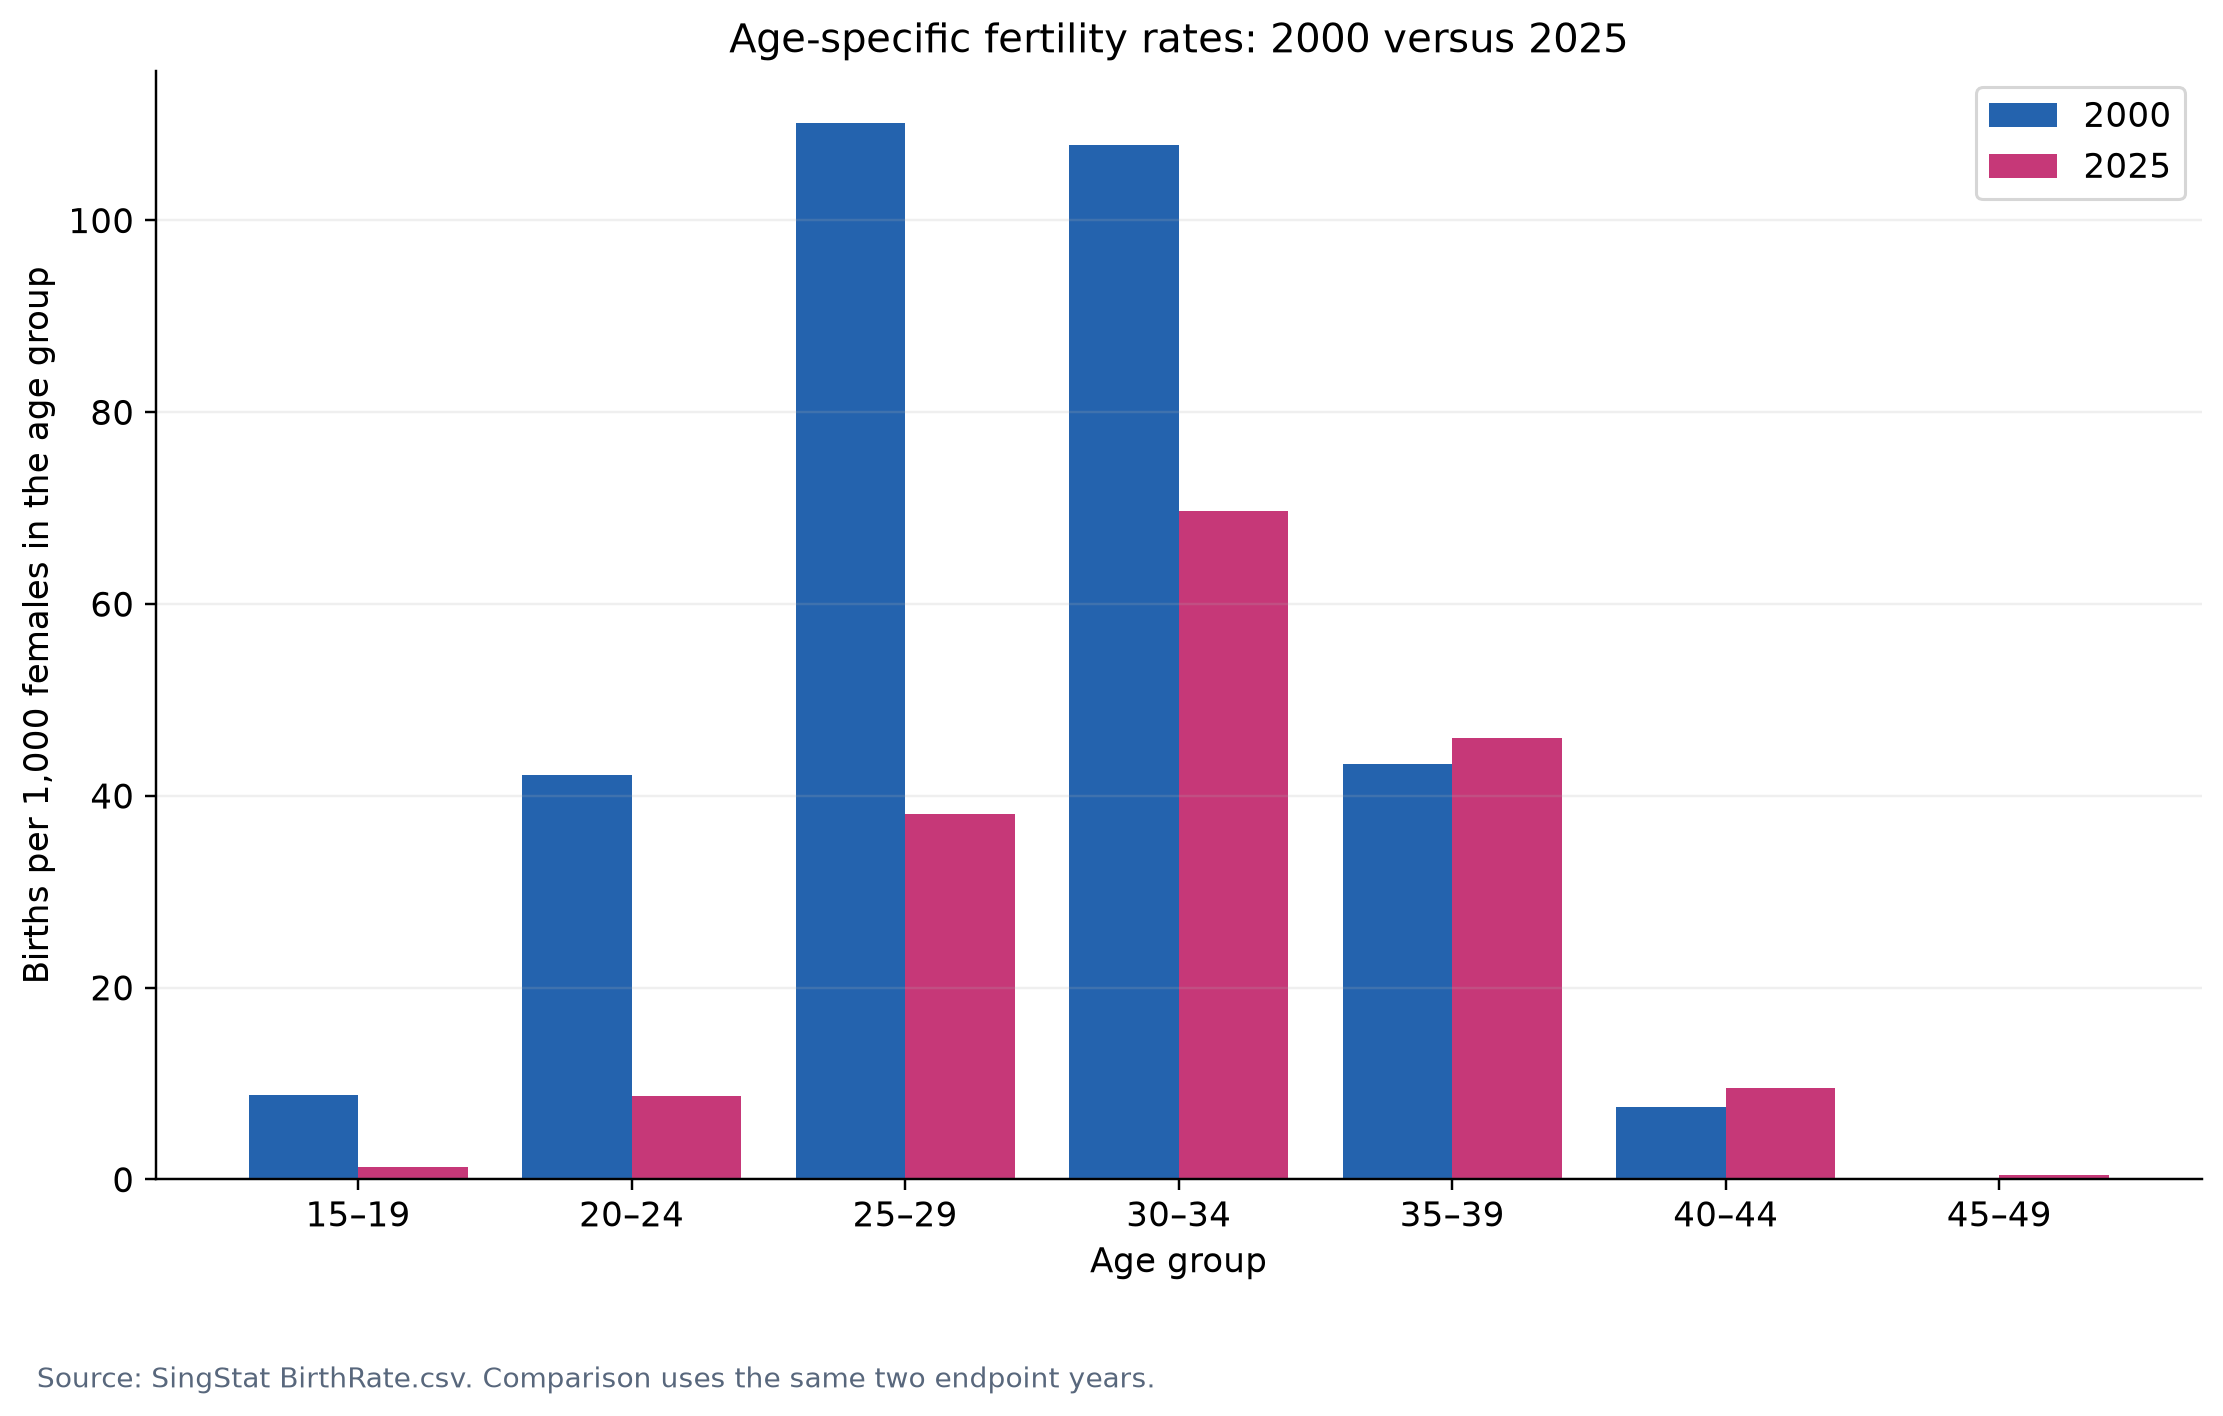

In [17]:
fig,ax=plt.subplots(figsize=(12,7));fig.subplots_adjust(bottom=.16)
x=np.arange(len(AGES))
ax.bar(x-.2,df.loc[0,AGES],width=.4,label='2000',color='#2463ae')
ax.bar(x+.2,df.loc[len(df)-1,AGES],width=.4,label='2025',color='#c63878')
ax.set(title='Age-specific fertility rates: 2000 versus 2025',ylabel='Births per 1,000 females in the age group',xlabel='Age group')
ax.set_xticks(x,LABELS);ax.legend();ax.grid(axis='y',alpha=.2)
save(fig,'04_age_fertility_bars.png','Source: SingStat BirthRate.csv. Comparison uses the same two endpoint years.')
display(Image(filename=str(OUT / '04_age_fertility_bars.png')))

## Figure 5: Correlation between HDB Resale Prices and Age-Specific Fertility Rates, 2000–2025

Pearson correlations are negative for women aged 15–19 (-0.900), 20–24 (-0.916), 25–29 (-0.879), and 30–34 (-0.572). They are positive for ages 35–39 (0.784), 40–44 (0.842), and 45–49 (0.825). These descriptive correlations reflect associations between annual levels and may be strongly influenced by shared time trends. A positive correlation for older ages does not mean that increasing house prices encourage childbirth; the underlying fertility levels are also much lower in the oldest groups.


Price growth, 2000–2025 (%)
HDB_Resale_Price_Index      159.17
Private_Landed_Index        145.47
Private_Non_Landed_Index    112.08
dtype: float64

Age-specific correlations with HDB prices:
 15 - 19 Years   -0.900
20 - 24 Years   -0.916
25 - 29 Years   -0.879
30 - 34 Years   -0.572
35 - 39 Years    0.784
40 - 44 Years    0.842
45 - 49 Years    0.825
dtype: float64


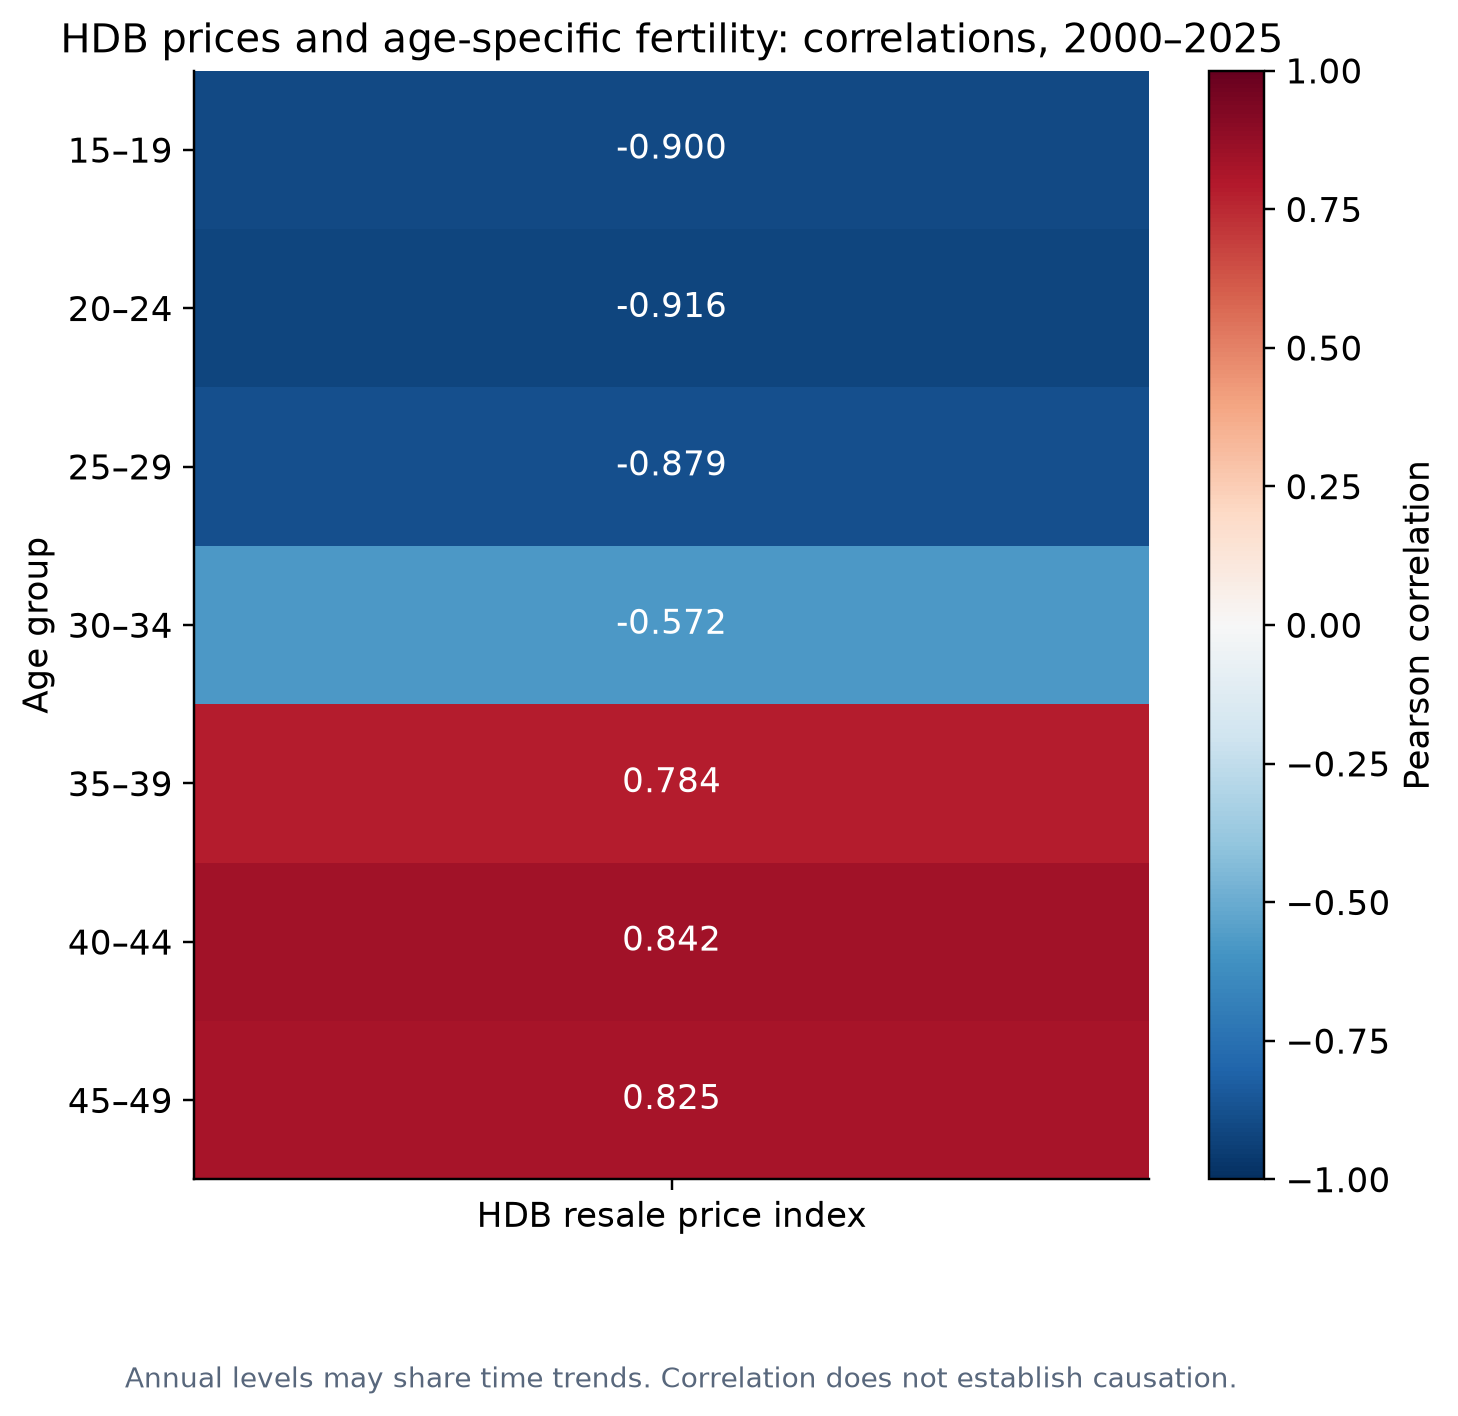

In [18]:
# 6. Pearson correlation of annual levels; descriptive, subject to time trends.
corr=df[AGES].corrwith(df.HDB_Resale_Price_Index)
corr.rename('Pearson_r').to_csv(OUT/'Age_HDB_Correlations.csv',index_label='Age_Group')
fig,ax=plt.subplots(figsize=(7,7));fig.subplots_adjust(bottom=.16)
img=ax.imshow(corr.to_numpy()[:,None],cmap='RdBu_r',vmin=-1,vmax=1,aspect='auto')
ax.set_xticks([0],['HDB resale price index']);ax.set_yticks(range(len(AGES)),LABELS)
ax.set(title='HDB prices and age-specific fertility: correlations, 2000–2025',ylabel='Age group')
for i,value in enumerate(corr):ax.text(0,i,f'{value:.3f}',ha='center',va='center',color='white' if abs(value)>.55 else 'black')
fig.colorbar(img,ax=ax,label='Pearson correlation')
save(fig,'05_age_hdb_heatmap.png','Annual levels may share time trends. Correlation does not establish causation.')
print('\nPrice growth, 2000–2025 (%)')
print(((df.loc[len(df)-1,price_cols]/df.loc[0,price_cols]-1)*100).round(2))
print('\nAge-specific correlations with HDB prices:\n',corr.round(3))
display(Image(filename=str(OUT / '05_age_hdb_heatmap.png')))

## Housing conclusion

Housing prices rose substantially while total fertility declined from 2000 to 2025. Age-specific patterns suggest a shift towards later childbearing, while the Census snapshot shows how households with children are distributed between HDB and private housing. Together, these results motivate further investigation of housing affordability and family formation. They do not demonstrate that housing prices cause lower fertility. Household income, housing expenditure, marriage timing and family circumstances would be needed for a more direct assessment.

# Part 3 · Marriage

Presenter: Tongtong Tang

Original data file `marriage_data.csv` is now read from `Fertility_Combined_Data.csv` with identical values.

# AN6100 Final Project — Marriage Factor and TFR

This notebook studies how **marriage timing and family-formation patterns are associated with Singapore's Total Fertility Rate (TFR)** from 2010 to 2025.

It contains five interactive Marriage charts plus a presentation-focused analysis of the shift from age **25–29 toward 30–34**.

### Controls
- `YEAR_START`, `YEAR_END`
- `CORR_MODE`: `"Levels"` or `"Yearly change"`
- `LINK_SERIES`
- `LINK_MODE`
- `LAG`

> Correlation is used to describe association, not direct causation.


In [19]:

from pathlib import Path
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from scipy.stats import pearsonr

# -------------------- v7-style settings --------------------
YEAR_START = 2010
YEAR_END = 2025

CORR_MODE = "Levels"        # "Levels" or "Yearly change"
LINK_SERIES = "F_Marriage_Rate_20_24"
LINK_MODE = "Levels"        # "Levels" or "Yearly change"
LAG = 0                     # 0, 1, 2, or 3 years

BLUE = "#2a78d6"
ORANGE = "#eb6834"
VIOLET = "#4a3aa7"
RED = "#e34948"
DIVERGING = [[0, BLUE], [0.5, "#efeeea"], [1, RED]]

RATES = {
    "F_Marriage_Rate_20_24": "20-24",
    "F_Marriage_Rate_25_29": "25-29",
    "F_Marriage_Rate_30_34": "30-34",
    "F_Marriage_Rate_35_39": "35-39",
    "F_Marriage_Rate_40_44": "40-44",
}

SHORT = {
    "F_Marriage_Rate_20_24": "Marriage rate 20-24",
    "F_Marriage_Rate_25_29": "Marriage rate 25-29",
    "F_Marriage_Rate_30_34": "Marriage rate 30-34",
    "F_Marriage_Rate_35_39": "Marriage rate 35-39",
    "F_Marriage_Rate_40_44": "Marriage rate 40-44",
    "Median_Age_First_Birth": "Age at 1st birth",
    "Brides_25_29": "Brides 25-29",
    "Brides_30_34": "Brides 30-34",
    "TFR": "TFR",
}

def find_data():
    candidates = [
        Path("marriage_data.csv"),
        Path.cwd() / "marriage_data.csv",
    ]
    for p in candidates:
        if p.exists():
            return p
    raise FileNotFoundError("Put marriage_data.csv in the same folder as this notebook.")

raw = load_section('marriage')   # combined notebook: read from Fertility_Combined_Data.csv
df = raw[raw["Year"].between(YEAR_START, YEAR_END)].copy().sort_values("Year")
s = df.set_index("Year")

def corr_test(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    good = np.isfinite(x) & np.isfinite(y)
    x, y = x[good], y[good]
    n = len(x)
    if n < 4 or np.std(x) == 0 or np.std(y) == 0:
        return np.nan, np.nan, n
    r, p = pearsonr(x, y)
    return float(r), float(p), n

def p_text(p):
    if np.isnan(p): return "–"
    if p < 0.001: return "<0.001"
    if p < 0.01: return f"{p:.3f}"
    return f"{p:.2f}"

def transform(frame, cols, mode):
    d = frame[cols].dropna()
    if mode == "Yearly change":
        full = d.reindex(range(int(d.index.min()), int(d.index.max()) + 1))
        return full.diff().dropna()
    return d

def corr_matrix(frame, cols, mode):
    m = transform(frame, cols, mode)
    c = pd.DataFrame(np.nan, index=cols, columns=cols)
    p = c.copy()
    n = c.copy()
    for a in cols:
        for b in cols:
            tmp = m[[a,b]].dropna()
            if a == b:
                rr, pp, nn = 1.0, 0.0, len(tmp)
            else:
                rr, pp, nn = corr_test(tmp[a], tmp[b])
            c.loc[a,b], p.loc[a,b], n.loc[a,b] = rr, pp, nn
    return c, p, n

def pair(data, x_col, mode="Levels", lag=0):
    ss = data.set_index("Year")
    xs = ss[x_col].dropna()
    ys = ss["TFR"].dropna()
    if lag:
        xs = xs.copy()
        xs.index = xs.index + lag
    d = pd.concat([xs.rename("x"), ys.rename("y")], axis=1).dropna()
    return transform(d, ["x","y"], mode)

peak = s[list(RATES)].dropna(how="all").idxmax(axis=1).map(RATES)
print(f"Selected years: {YEAR_START}–{YEAR_END} ({len(df)} observations)")


Selected years: 2010–2025 (16 observations)


## Figure 1 — Women's marriage rate by age

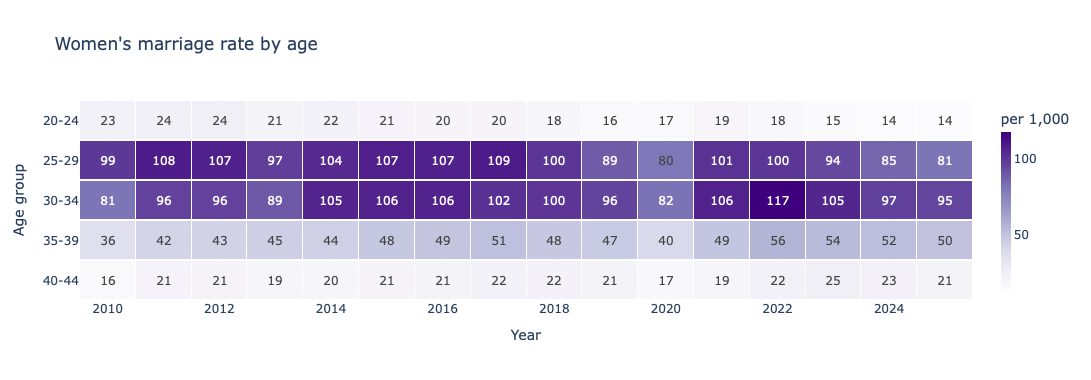

In [20]:

z = s[list(RATES)].dropna(how="all").T

fig = go.Figure(go.Heatmap(
    z=z.values,
    x=z.columns,
    y=list(RATES.values()),
    colorscale="Purples",
    xgap=1, ygap=2,
    text=np.round(z.values, 0),
    texttemplate="%{text:.0f}",
    colorbar=dict(title="per 1,000", thickness=10),
    hovertemplate="Age %{y}, %{x}: %{z:.1f}<extra></extra>"
))
fig.update_layout(
    title="Women's marriage rate by age",
    template="plotly_white",
    height=380
)
fig.update_yaxes(autorange="reversed", title_text="Age group")
fig.update_xaxes(title_text="Year")
fig.show()


### Insight

In [21]:
y0, y1 = int(df["Year"].min()), int(df["Year"].max())
r20_0 = s.loc[y0, "F_Marriage_Rate_20_24"]
r20_1 = s.loc[y1, "F_Marriage_Rate_20_24"]
r30_0 = s.loc[y0, "F_Marriage_Rate_30_34"]
r30_1 = s.loc[y1, "F_Marriage_Rate_30_34"]

print(
    f"From {y0} to {y1}, the female marriage rate at age 20–24 falls from "
    f"{r20_0:.1f} to {r20_1:.1f} per 1,000 unmarried women, while the 30–34 rate "
    f"moves from {r30_0:.1f} to {r30_1:.1f}. The peak marriage-rate group shifts "
    f"from {peak.iloc[0]} to {peak.iloc[-1]}, indicating later marriage timing."
)


From 2010 to 2025, the female marriage rate at age 20–24 falls from 22.6 to 13.7 per 1,000 unmarried women, while the 30–34 rate moves from 81.0 to 94.9. The peak marriage-rate group shifts from 25-29 to 30-34, indicating later marriage timing.


## Figure 2 — Peak marriage age and first-birth timing

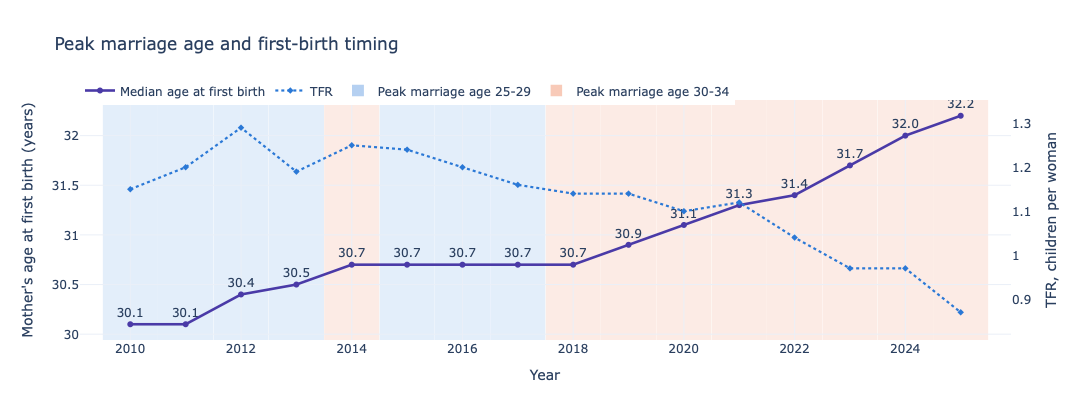

In [22]:

PEAK_COL = {"25-29": BLUE, "30-34": ORANGE}
d = df.dropna(subset=["Median_Age_First_Birth"]).set_index("Year")
counts = [
    d.loc[y, "Brides_25_29"] if peak.get(y) == "25-29" else d.loc[y, "Brides_30_34"]
    for y in d.index
]

fig = go.Figure()
for yr, group in peak.items():
    fig.add_vrect(
        x0=yr-0.5, x1=yr+0.5,
        fillcolor=PEAK_COL.get(group, "#ffffff"),
        opacity=0.13, layer="below", line_width=0
    )

fig.add_trace(go.Scatter(
    x=d.index,
    y=d["Median_Age_First_Birth"],
    name="Median age at first birth",
    mode="lines+markers+text",
    text=[f"{v:.1f}" for v in d["Median_Age_First_Birth"]],
    textposition="top center",
    line=dict(color=VIOLET, width=2.6),
    marker=dict(size=6),
    customdata=np.c_[peak.reindex(d.index).values, counts],
    hovertemplate=(
        "%{x}: first birth at %{y:.1f}<br>"
        "peak marriage age %{customdata[0]} "
        "(%{customdata[1]:,.0f} brides)<extra></extra>"
    )
))

# TFR on the right axis
t = df.dropna(subset=["TFR"])
fig.add_trace(go.Scatter(
    x=t["Year"], y=t["TFR"],
    name="TFR",
    yaxis="y2",
    mode="lines+markers",
    line=dict(color=BLUE, width=2.2, dash="dot"),
    marker=dict(size=5, symbol="diamond"),
    hovertemplate="TFR %{y:.2f}<extra></extra>"
))

for group, color in PEAK_COL.items():
    fig.add_trace(go.Scatter(
        x=[None], y=[None],
        mode="markers",
        name=f"Peak marriage age {group}",
        marker=dict(size=12, symbol="square", color=color, opacity=0.35)
    ))

lo, hi = t["TFR"].min(), t["TFR"].max()
pad = max((hi-lo)*0.15, 0.03)

fig.update_layout(
    title="Peak marriage age and first-birth timing",
    template="plotly_white",
    height=420,
    yaxis=dict(title="Mother's age at first birth (years)"),
    yaxis2=dict(
        title="TFR, children per woman",
        overlaying="y", side="right", showgrid=False,
        range=[lo-pad, hi+pad]
    ),
    legend=dict(orientation="h", y=1.10, x=0)
)
fig.update_xaxes(title_text="Year")
fig.show()


### Insight

In [23]:
fb0 = d["Median_Age_First_Birth"].iloc[0]
fb1 = d["Median_Age_First_Birth"].iloc[-1]
tfr0 = t["TFR"].iloc[0]
tfr1 = t["TFR"].iloc[-1]

print(
    f"The peak marriage age shifts from {peak.iloc[0]} to {peak.iloc[-1]}. "
    f"At the same time, median age at first birth rises from {fb0:.1f} to {fb1:.1f} years, "
    f"while TFR moves from {tfr0:.2f} to {tfr1:.2f}. This supports an association between "
    "later family formation and lower fertility, but does not prove causation."
)


The peak marriage age shifts from 25-29 to 30-34. At the same time, median age at first birth rises from 30.1 to 32.2 years, while TFR moves from 1.15 to 0.87. This supports an association between later family formation and lower fertility, but does not prove causation.


## Figure 3 — Brides aged 25–29 vs 30–34

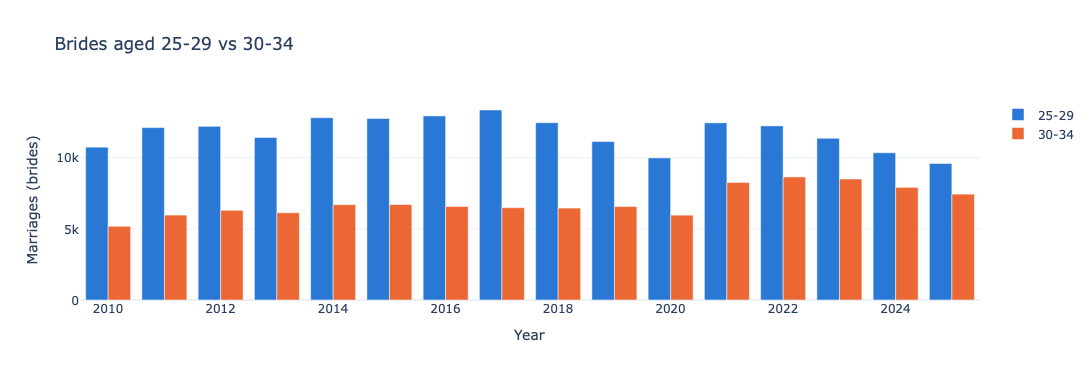

In [24]:

d3 = df.dropna(subset=["Brides_25_29", "Brides_30_34"])

fig = go.Figure()
fig.add_trace(go.Bar(
    x=d3["Year"], y=d3["Brides_25_29"],
    name="25-29", marker_color=BLUE,
    hovertemplate="%{x}, brides 25-29: %{y:,.0f}<extra></extra>"
))
fig.add_trace(go.Bar(
    x=d3["Year"], y=d3["Brides_30_34"],
    name="30-34", marker_color=ORANGE,
    hovertemplate="%{x}, brides 30-34: %{y:,.0f}<extra></extra>"
))
fig.update_layout(
    title="Brides aged 25-29 vs 30-34",
    template="plotly_white",
    height=380,
    barmode="group"
)
fig.update_xaxes(title_text="Year")
fig.update_yaxes(title_text="Marriages (brides)")
fig.show()


### Insight

In [25]:
print(
    f"Actual brides aged 25–29 change from {d3['Brides_25_29'].iloc[0]:,.0f} to "
    f"{d3['Brides_25_29'].iloc[-1]:,.0f}, while brides aged 30–34 change from "
    f"{d3['Brides_30_34'].iloc[0]:,.0f} to {d3['Brides_30_34'].iloc[-1]:,.0f}. "
    "These counts reinforce the ageing pattern, although marriage rates are still the better "
    "measure for comparing marriage propensity because counts depend on age-group population size."
)


Actual brides aged 25–29 change from 10,748 to 9,601, while brides aged 30–34 change from 5,185 to 7,444. These counts reinforce the ageing pattern, although marriage rates are still the better measure for comparing marriage propensity because counts depend on age-group population size.


## Figure 4 — Key correlations: marriage timing and TFR

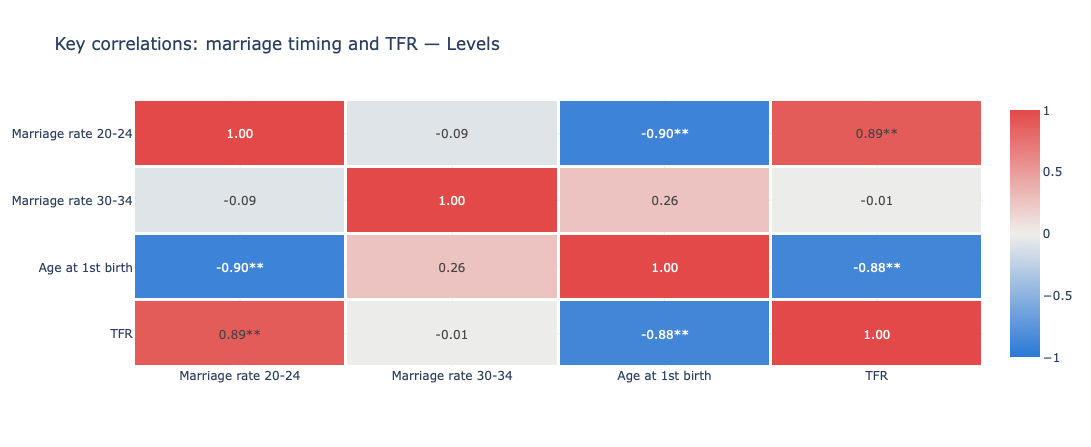

In [26]:

KEY = [
    "F_Marriage_Rate_20_24",
    "F_Marriage_Rate_30_34",
    "Median_Age_First_Birth",
    "TFR"
]
c, p, n = corr_matrix(s, KEY, CORR_MODE)
names = [SHORT[k] for k in KEY]

text = []
hover = []
for i in range(len(KEY)):
    tr, hr = [], []
    for j in range(len(KEY)):
        sig = ""
        if i != j and not np.isnan(p.iloc[i,j]):
            sig = "**" if p.iloc[i,j] < 0.01 else "*" if p.iloc[i,j] < 0.05 else ""
        tr.append(f"{c.iloc[i,j]:.2f}{sig}" if not np.isnan(c.iloc[i,j]) else "–")
        hr.append(f"p = {p_text(p.iloc[i,j])}, {int(n.iloc[i,j])} years")
    text.append(tr)
    hover.append(hr)

fig = go.Figure(go.Heatmap(
    z=c.values, x=names, y=names,
    colorscale=DIVERGING, zmin=-1, zmax=1,
    xgap=3, ygap=3,
    text=text, texttemplate="%{text}",
    customdata=hover,
    hovertemplate="%{y} vs %{x}: r = %{z:.2f}<br>%{customdata}<extra></extra>"
))
fig.update_layout(
    title=f"Key correlations: marriage timing and TFR — {CORR_MODE}",
    template="plotly_white",
    height=430
)
fig.update_yaxes(autorange="reversed")
fig.show()


### Insight

In [27]:
r20 = c.loc["F_Marriage_Rate_20_24", "TFR"]
r30 = c.loc["F_Marriage_Rate_30_34", "TFR"]
rfb = c.loc["Median_Age_First_Birth", "TFR"]

print(
    f"Using {CORR_MODE.lower()}, the 20–24 marriage rate vs TFR is r={r20:+.2f}, "
    f"the raw 30–34 marriage rate vs TFR is r={r30:+.2f}, and median age at first birth "
    f"vs TFR is r={rfb:+.2f}. The raw 30–34 rate alone does not capture the timing shift, "
    "which is why the relative movement from 25–29 toward 30–34 is analysed separately below."
)


Using levels, the 20–24 marriage rate vs TFR is r=+0.89, the raw 30–34 marriage rate vs TFR is r=-0.01, and median age at first birth vs TFR is r=-0.88. The raw 30–34 rate alone does not capture the timing shift, which is why the relative movement from 25–29 toward 30–34 is analysed separately below.


## Figure 5 — Marriage vs TFR

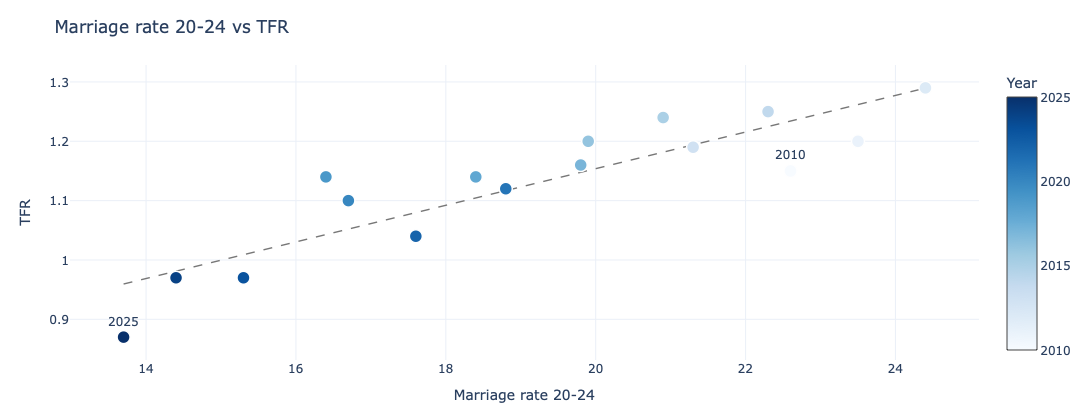

Insight — Marriage rate 20-24: r=+0.89, p=<0.001, n=16 (significant).


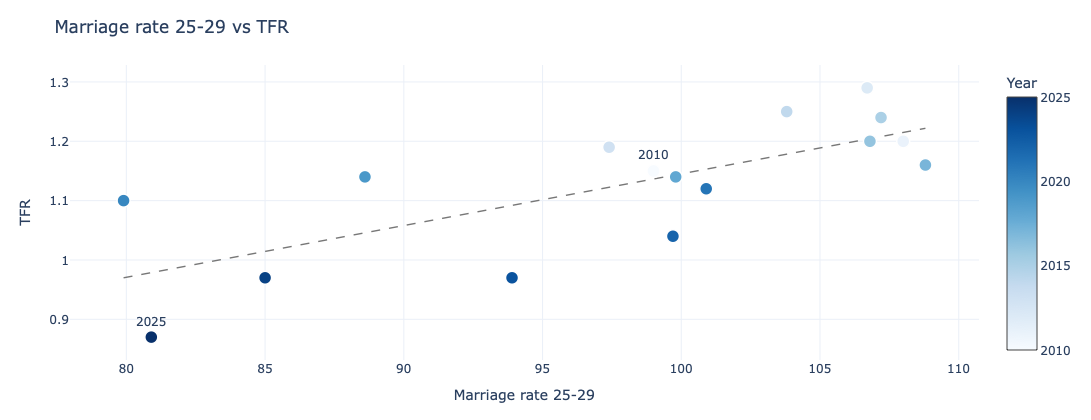

Insight — Marriage rate 25-29: r=+0.74, p=0.001, n=16 (significant).


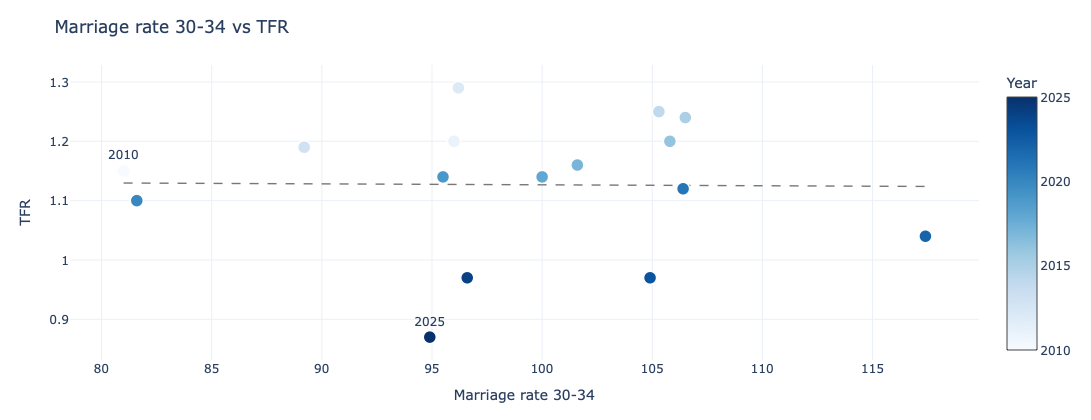

Insight — Marriage rate 30-34: r=-0.01, p=0.96, n=16 (not significant).


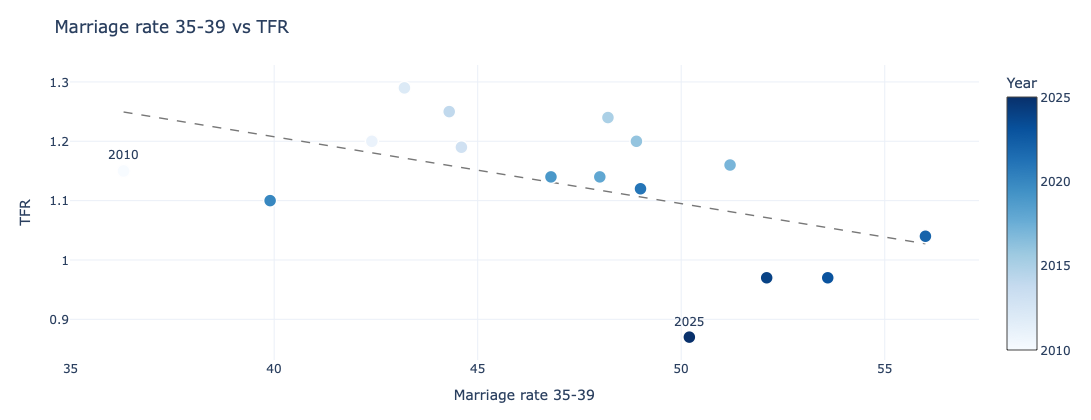

Insight — Marriage rate 35-39: r=-0.51, p=0.04, n=16 (significant).


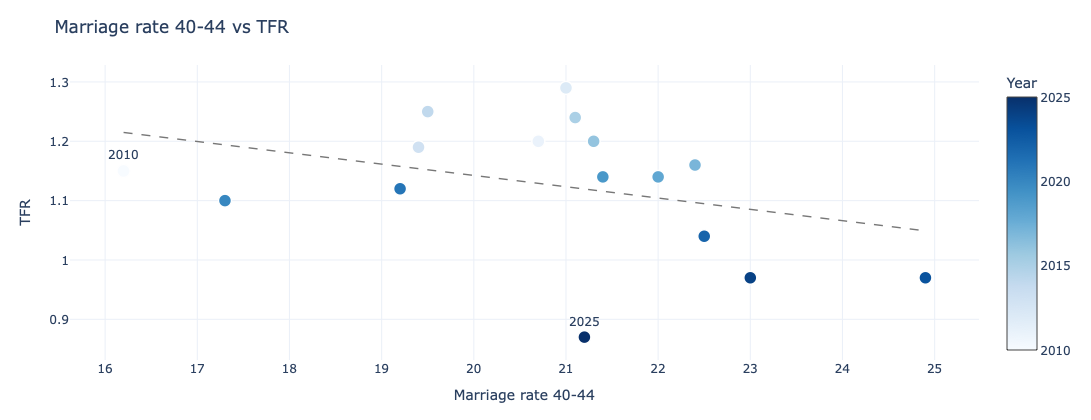

Insight — Marriage rate 40-44: r=-0.36, p=0.17, n=16 (not significant).


,Age group,r vs TFR,p-value,n,Significant (p<0.05)
0,20-24,0.886,<0.001,16,Yes
1,25-29,0.739,0.001,16,Yes
2,30-34,-0.013,0.96,16,No
3,35-39,-0.512,0.04,16,Yes
4,40-44,-0.359,0.17,16,No


In [28]:

# Figure 5 now shows ALL female age-specific marriage-rate groups vs TFR.

AGE_RATE_SERIES = [
    "F_Marriage_Rate_20_24",
    "F_Marriage_Rate_25_29",
    "F_Marriage_Rate_30_34",
    "F_Marriage_Rate_35_39",
    "F_Marriage_Rate_40_44",
]

age_summary = []

for series in AGE_RATE_SERIES:
    d5 = pair(df, series, LINK_MODE, LAG)

    if len(d5) < 4:
        print(f"{SHORT[series]}: not enough overlapping years.")
        continue

    r5, p5, n5 = corr_test(d5["x"], d5["y"])

    # Regression line
    b, a = np.polyfit(d5["x"], d5["y"], 1)
    xs = np.linspace(d5["x"].min(), d5["x"].max(), 50)

    fig = go.Figure()

    if LINK_MODE != "Levels":
        fig.add_hline(y=0, line=dict(color="#cccccc", width=1))
        fig.add_vline(x=0, line=dict(color="#cccccc", width=1))

    fig.add_trace(
        go.Scatter(
            x=xs,
            y=a + b * xs,
            mode="lines",
            line=dict(color="#777777", dash="dash", width=1.4),
            hoverinfo="skip",
            showlegend=False,
        )
    )

    years = d5.index.values
    ends = {years.min(), years.max()}

    fig.add_trace(
        go.Scatter(
            x=d5["x"],
            y=d5["y"],
            mode="markers+text",
            text=[str(y) if y in ends else "" for y in years],
            textposition="top center",
            customdata=years,
            marker=dict(
                size=13,
                color=years,
                colorscale="Blues",
                line=dict(color="white", width=1.5),
                showscale=True,
                colorbar=dict(title="Year"),
            ),
            hovertemplate=(
                "<b>%{customdata}</b><br>"
                + SHORT[series]
                + ": %{x:,.2f}<br>TFR: %{y:,.3f}<extra></extra>"
            ),
            showlegend=False,
        )
    )

    suffix = "" if LINK_MODE == "Levels" else " (change vs previous year)"

    fig.update_layout(
        title=f"{SHORT[series]} vs TFR",
        template="plotly_white",
        height=420,
        margin=dict(l=70, r=50, t=65, b=60),
    )
    fig.update_xaxes(title_text=SHORT[series] + suffix)
    fig.update_yaxes(
        title_text=("TFR" + (f" {LAG} yr later" if LAG else "")) + suffix
    )

    fig.show()

    significance = (
        "significant" if not np.isnan(p5) and p5 < 0.05
        else "not significant"
    )

    print(
        f"Insight — {SHORT[series]}: r={r5:+.2f}, "
        f"p={p_text(p5)}, n={n5} ({significance})."
    )

    age_summary.append({
        "Age group": SHORT[series].replace("Marriage rate ", ""),
        "r vs TFR": round(r5, 3),
        "p-value": p_text(p5),
        "n": n5,
        "Significant (p<0.05)": "Yes" if significance == "significant" else "No",
    })

# Summary table across all age groups
age_summary_df = pd.DataFrame(age_summary)
display(age_summary_df)


### Insight

In [29]:

# Overall Figure 5 interpretation
if not age_summary_df.empty:
    strongest = age_summary_df.iloc[age_summary_df["r vs TFR"].abs().argmax()]
    print(
        "Overall insight: the relationship with TFR is not the same across age groups. "
        f"The strongest absolute correlation in the selected setting is for age {strongest['Age group']} "
        f"(r={strongest['r vs TFR']:+.2f}, p={strongest['p-value']}). "
        "This comparison helps distinguish which part of the marriage-age profile is most closely associated with TFR."
    )


Overall insight: the relationship with TFR is not the same across age groups. The strongest absolute correlation in the selected setting is for age 20-24 (r=+0.89, p=<0.001). This comparison helps distinguish which part of the marriage-age profile is most closely associated with TFR.


## Figure 6 — Relative shift toward age 30–34 vs TFR

To measure **later marriage timing** more directly, this figure uses a relative shift index:

\[
	ext{Later-marriage shift index}
=

rac{	ext{Female marriage rate age 30–34}}
{	ext{Female marriage rate age 25–29}}
\]

- **Index < 1:** the 25–29 marriage rate is still higher.
- **Index > 1:** the 30–34 marriage rate is higher.

This is more useful than the raw 30–34 marriage rate alone because it measures the **relative movement of the marriage-rate peak toward an older age group**.


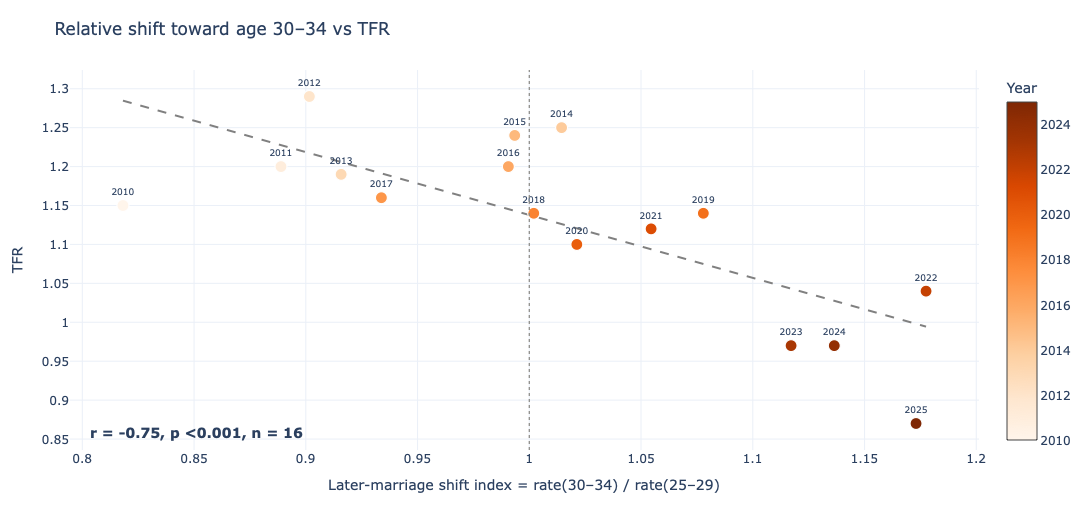

In [30]:

shift = df[
    ["Year", "TFR", "F_Marriage_Rate_25_29", "F_Marriage_Rate_30_34"]
].dropna().copy()

shift["Later_Marriage_Shift_Index"] = (
    shift["F_Marriage_Rate_30_34"] /
    shift["F_Marriage_Rate_25_29"]
)

r_shift, p_shift, n_shift = corr_test(
    shift["Later_Marriage_Shift_Index"],
    shift["TFR"]
)

# Best-fit line
b, a = np.polyfit(
    shift["Later_Marriage_Shift_Index"],
    shift["TFR"],
    1
)

xs = np.linspace(
    shift["Later_Marriage_Shift_Index"].min(),
    shift["Later_Marriage_Shift_Index"].max(),
    100
)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=xs,
        y=a + b * xs,
        mode="lines",
        line=dict(
            color="#808080",
            dash="dash",
            width=2
        ),
        hoverinfo="skip",
        showlegend=False
    )
)

# Reference line: x = 1 means both age groups have the same marriage rate
fig.add_vline(
    x=1,
    line_dash="dot",
    line_color="#8a8984",
    line_width=1.2
)

fig.add_trace(
    go.Scatter(
        x=shift["Later_Marriage_Shift_Index"],
        y=shift["TFR"],
        mode="markers+text",
        text=shift["Year"].astype(int).astype(str),
        textposition="top center",
        textfont=dict(size=9),
        customdata=shift["Year"].astype(int),
        marker=dict(
            size=12,
            color=shift["Year"],
            colorscale="Oranges",
            cmin=shift["Year"].min(),
            cmax=shift["Year"].max(),
            line=dict(color="white", width=1.2),
            colorbar=dict(title="Year")
        ),
        hovertemplate=(
            "<b>%{customdata}</b><br>"
            "Later-marriage shift index: %{x:.3f}<br>"
            "TFR: %{y:.2f}<extra></extra>"
        ),
        showlegend=False
    )
)

fig.add_annotation(
    xref="paper",
    yref="paper",
    x=0.02,
    y=0.02,
    text=f"<b>r = {r_shift:.2f}, p {p_text(p_shift)}, n = {n_shift}</b>",
    showarrow=False,
    font=dict(size=14),
    align="left"
)

fig.update_layout(
    title="Relative shift toward age 30–34 vs TFR",
    template="plotly_white",
    height=520,
    margin=dict(l=70, r=90, t=70, b=70)
)

fig.update_xaxes(
    title_text="Later-marriage shift index = rate(30–34) / rate(25–29)",
    showgrid=True
)

fig.update_yaxes(
    title_text="TFR",
    showgrid=True
)

fig.show()


### Insight

In [31]:

first = shift.iloc[0]
last = shift.iloc[-1]

significance = (
    "statistically significant"
    if p_shift < 0.05
    else "not statistically significant"
)

print(
    f"The later-marriage shift index increases from "
    f"{first['Later_Marriage_Shift_Index']:.2f} in {int(first['Year'])} to "
    f"{last['Later_Marriage_Shift_Index']:.2f} in {int(last['Year'])}. "
    f"Across {int(first['Year'])}–{int(last['Year'])}, the index is negatively correlated "
    f"with TFR (r={r_shift:+.2f}, p={p_text(p_shift)}, n={n_shift}), and the relationship is "
    f"{significance}. A higher index means marriage is relatively more concentrated among women "
    f"aged 30–34 than 25–29. This supports an association between later family formation and lower TFR, "
    "but it does not prove that later marriage directly causes lower fertility."
)


The later-marriage shift index increases from 0.82 in 2010 to 1.17 in 2025. Across 2010–2025, the index is negatively correlated with TFR (r=-0.75, p=<0.001, n=16), and the relationship is statistically significant. A higher index means marriage is relatively more concentrated among women aged 30–34 than 25–29. This supports an association between later family formation and lower TFR, but it does not prove that later marriage directly causes lower fertility.


# Part 4 · Income & inequality

Presenter: Wang Gaoyang

The cleaned income columns are read from `Fertility_Combined_Data.csv`. How they were built from the raw SingStat tables (17872, M213751, 17885, 17892, M810361, M810091) is shown step by step in `members/4_Income_WangGaoyang/Income_WangGaoyang.ipynb`.

In [2]:
import numpy as np
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy.stats import pearsonr

pio.renderers.default = 'plotly_mimetype+notebook_connected'
Y0, Y1 = 2010, 2025
clean = load_section('income').set_index('Year')   # combined notebook: read from Fertility_Combined_Data.csv
clean.round(3)

,TFR,PM_Avg,PM_Median,CPI_All_Items_2024_100,CPI_All_Items_2010_100,PM_Avg_Real_2010,PM_Median_Real_2010,Real_Growth_%,Real_Growth_D1,Real_Growth_D2,...,Real_Growth_D4,Real_Growth_D5,Real_Growth_D6,Real_Growth_D7,Real_Growth_D8,Real_Growth_D9,Gini_Before_Transfers,Gini_After_Transfers,Real_Growth_D1_M810361,Real_Growth_D10_M810361
Year,,,,,,,,,,,,,,,,,,,,,
2010,1.15,2711.0,1850.0,75.099,100.000,2711.00,1850.00,4.4,4.2,5.6,...,5.1,3.8,3.5,3.3,3.4,4.0,0.472,0.425,4.2,4.8
2011,1.20,2927.0,1997.0,79.043,105.251,2780.97,1897.37,2.6,5.8,4.0,...,2.6,2.4,2.4,2.2,1.8,1.0,0.473,0.423,5.8,3.2
2012,1.29,3145.0,2129.0,82.664,110.073,2857.21,1934.18,2.7,-1.2,1.0,...,2.3,2.1,1.9,1.4,1.1,1.6,0.478,0.432,-1.2,5.1
2013,1.19,3207.0,2250.0,84.618,112.675,2846.24,1996.89,-0.4,2.4,1.9,...,3.1,3.6,3.0,2.6,2.4,1.5,0.463,0.409,2.4,-5.2
2014,1.25,3421.0,2383.0,85.492,113.839,3005.12,2093.30,5.6,5.1,6.7,...,5.8,4.8,4.6,4.6,4.6,5.6,0.464,0.411,5.1,6.6
2015,1.24,3629.0,2503.0,85.046,113.245,3204.56,2210.25,6.6,10.7,8.3,...,6.7,5.9,6.2,6.3,5.7,5.8,0.463,0.409,10.7,7.3
2016,1.20,3694.0,2591.0,84.596,112.645,3279.33,2300.15,2.3,1.4,3.4,...,2.4,3.3,3.5,3.8,4.3,3.2,0.458,0.401,1.4,0.3
2017,1.16,3843.0,2706.0,85.084,113.295,3392.04,2388.46,3.4,2.1,2.8,...,3.0,3.6,4.0,3.7,3.8,4.5,0.459,0.402,2.1,2.6
2018,1.14,3977.0,2799.0,85.457,113.792,3494.98,2459.75,3.0,2.7,2.6,...,3.4,3.2,2.5,3.2,4.0,4.0,0.458,0.403,2.7,2.3


## Step 2 · Statistics helpers and chart style (same as the dashboard)

In [3]:
BLUE, ORANGE, AQUA, VIOLET, GOLD, RED = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#c98a00", "#e34948"
MUTED, GRID, LIGHT = "#6b6a66", "#ececea", "#d4d3cd"
DIVERGING = [[0, BLUE], [0.5, "#efeeea"], [1, RED]]
df = clean.reset_index()
T = clean.TFR


def pair(x, mode="Levels", lag=0):
    """x[t] against TFR[t+lag]; for 'Yearly change' both are differenced (this year minus last year)."""
    xs = clean[x].dropna().copy(); xs.index = xs.index + lag
    d = pd.concat([xs.rename("x"), T.rename("y")], axis=1).dropna()
    if mode == "Yearly change":
        d = d.reindex(range(d.index.min(), d.index.max() + 1)).diff().dropna()
    return d


def r_of(x, mode="Levels", lag=0):
    d = pair(x, mode, lag)
    r, p = pearsonr(d.x, d.y)
    return r, p, len(d)


def p_text(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}" if p < 0.01 else f"{p:.2f}"


def style(fig, h=380):
    fig.update_layout(height=h, template="plotly_white", margin=dict(l=10, r=10, t=60, b=10), font=dict(size=12),
                      legend=dict(orientation="h", yanchor="bottom", y=1.0, x=0, title=None), hovermode="x unified")
    fig.update_xaxes(showgrid=False); fig.update_yaxes(gridcolor=GRID, zeroline=False)
    return fig


def add_tfr_axis(fig):
    fig.add_trace(go.Scatter(x=df.Year, y=df.TFR, name="TFR (right axis)", yaxis="y2", mode="lines+markers",
                             line=dict(color=BLUE, width=2.8, dash="dot"), marker=dict(size=5, symbol="diamond"),
                             hovertemplate="TFR %{y:.2f}<extra></extra>"))
    lo, hi = df.TFR.min(), df.TFR.max(); pad = (hi - lo) * 0.15
    fig.update_layout(yaxis2=dict(title=dict(text="TFR, children per woman", font=dict(color=BLUE)), overlaying="y",
                                  side="right", showgrid=False, tickformat=".2f", tickfont=dict(color=BLUE),
                                  range=[lo - pad, hi + pad]))
    return fig

## Chart 1 · Income per household member: nominal and real

Source: SingStat 17872, M213751, M810091 · Real = nominal ÷ CPI (2010 = 100) × 100.

In [4]:
fig = go.Figure()
for c, n, col, dash in [("PM_Median", "Median, nominal", ORANGE, "solid"), ("PM_Median_Real_2010", "Median, real (2010 S$)", AQUA, "solid"),
                        ("PM_Avg", "Average, nominal", ORANGE, "dash"), ("PM_Avg_Real_2010", "Average, real (2010 S$)", AQUA, "dash")]:
    fig.add_trace(go.Scatter(x=df.Year, y=df[c], name=n, mode="lines+markers", line=dict(color=col, width=2.6, dash=dash),
                             marker=dict(size=5), hovertemplate=n + " S$%{y:,.0f}<extra></extra>"))
    fig.add_annotation(x=Y1, y=df[c].iloc[-1], text=f"<b>S${df[c].iloc[-1]:,.0f}</b>", showarrow=False, xanchor="left",
                       xshift=6, yshift=-7 if "real" in n else 7, font=dict(color=col, size=11))
fig.update_yaxes(title_text="S$ per member per month", tickprefix="$", tickformat=",.0f")
fig.update_xaxes(range=[Y0 - 0.5, Y1 + 1.6])
fig.update_layout(title="Income per household member: nominal and real (resident employed households)")
add_tfr_axis(style(fig, 440)).show()

for c in ["PM_Median", "PM_Median_Real_2010", "PM_Avg", "PM_Avg_Real_2010"]:
    print(f"{c:22s} {Y0}: S${clean[c].loc[Y0]:,.0f}  {Y1}: S${clean[c].loc[Y1]:,.0f}  ({(clean[c].loc[Y1] / clean[c].loc[Y0] - 1) * 100:+.0f}%)")
print(f"TFR {Y0}: {T.loc[Y0]:.2f}  {Y1}: {T.loc[Y1]:.2f}  ({(T.loc[Y1] / T.loc[Y0] - 1) * 100:+.0f}%)")

PM_Median              2010: S$1,850  2025: S$3,909  (+111%)
PM_Median_Real_2010    2010: S$1,850  2025: S$2,909  (+57%)
PM_Avg                 2010: S$2,711  2025: S$5,173  (+91%)
PM_Avg_Real_2010       2010: S$2,711  2025: S$3,850  (+42%)
TFR 2010: 1.15  2025: 0.87  (-24%)


**Findings.**
- Median income per member rose from S\$1,850 (2010) to S\$3,909 (2025), **+111%**. After inflation it is S\$2,909 in 2010 dollars, **+57%**.
- The average rose from S\$2,711 to S\$5,173 (+91%), or S\$3,850 in 2010 dollars (+42%).
- Over the same years TFR fell from 1.15 to 0.87 (−24%). Households became richer in real terms while births fell, so a lack of income is not what lowered the birth rate.

## Chart 2 · Real income growth by income group

Source: SingStat 17885 · real % change in average income per member vs the previous year; D1–D9 = income deciles.

In [5]:
cols = ["Real_Growth_%"] + [f"Real_Growth_D{i}" for i in range(1, 10)]
z = clean[cols].dropna(how="all").T
fig = go.Figure(go.Heatmap(z=z.values, x=z.columns, y=["<b>All households</b>", "D1 lowest"] + [f"D{i}" for i in range(2, 10)],
                           colorscale=[[0, RED], [7 / 18, "#efeeea"], [1, BLUE]], zmin=-7, zmax=11, xgap=1, ygap=1,
                           text=np.round(z.values, 1), texttemplate="%{text:.1f}", textfont=dict(size=9),
                           colorbar=dict(title="%", thickness=10), hovertemplate="%{y}, %{x}: %{z:+.1f}%<extra></extra>"))
fig.add_hline(y=0.5, line=dict(color="white", width=4))
fig.update_yaxes(autorange="reversed")
fig.update_layout(title="Real income growth by income group (% vs previous year)")
style(fig, 420).show()

g = clean.loc[Y0:2024]
low, high = g[["Real_Growth_D1", "Real_Growth_D2", "Real_Growth_D3"]].mean(axis=1), g[["Real_Growth_D7", "Real_Growth_D8", "Real_Growth_D9"]].mean(axis=1)
print("years when every group fell:", [y for y in g.index if (g.loc[y, cols] < 0).all()])
print("years when all households fell:", g.index[g["Real_Growth_%"] < 0].tolist())
print(f"average yearly real growth: D1-D3 {low.mean():.1f}%, D7-D9 {high.mean():.1f}%; D1-D3 grew faster in {(low > high).sum()} of {len(g)} years")

years when every group fell: [2020]
years when all households fell: [2013, 2020]
average yearly real growth: D1-D3 3.2%, D7-D9 2.6%; D1-D3 grew faster in 8 of 15 years


**Findings.**
- Real income grew in almost every year for almost every group. All households together fell only in 2013 and 2020; **2020 is the only year every group fell**.
- Lower-income groups grew a little faster: D1–D3 averaged 3.2% a year against 2.6% for D7–D9 (2010–2024), faster in 8 of 15 years — consistent with the falling Gini in Chart 3.
- Rising real income across the whole distribution did not stop TFR falling.

## Chart 3 · Gini coefficient before and after transfers & taxes, with TFR on top

Source: SingStat 17892, M810091 · 0 = everyone has the same income, 1 = one household has everything.

In [6]:
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.3, 0.7], vertical_spacing=0.06)
fig.add_trace(go.Scatter(x=df.Year, y=df.TFR, name="TFR", mode="lines+markers", line=dict(color=BLUE, width=2.4),
                         marker=dict(size=5, symbol="diamond")), row=1, col=1)
for c, n, col in [("Gini_Before_Transfers", "Before transfers & taxes", VIOLET), ("Gini_After_Transfers", "After transfers & taxes", GOLD)]:
    fig.add_trace(go.Scatter(x=df.Year, y=df[c], name=n, mode="lines+markers", line=dict(color=col, width=3), marker=dict(size=6),
                             hovertemplate=n + " %{y:.3f}<extra></extra>"), row=2, col=1)
    for y, anc in [(Y0, "right"), (Y1, "left")]:
        fig.add_annotation(x=y, y=clean.loc[y, c], text=f"<b>{clean.loc[y, c]:.3f}</b>", showarrow=False, xanchor=anc,
                           xshift=-7 if anc == "right" else 7, font=dict(color=col), row=2, col=1)
fig.update_xaxes(range=[Y0 - 1.6, Y1 + 1.6])
fig.update_yaxes(title_text="TFR", row=1, col=1); fig.update_yaxes(title_text="Gini", tickformat=".2f", row=2, col=1)
fig.update_layout(title="Income inequality (Gini) before and after transfers & taxes, with TFR")
style(fig, 500).show()
print(clean[["Gini_Before_Transfers", "Gini_After_Transfers"]].loc[[2010, 2012, 2019, 2020, 2025]])

      Gini_Before_Transfers  Gini_After_Transfers
Year                                             
2010                  0.472                 0.425
2012                  0.478                 0.432
2019                  0.452                 0.398
2020                  0.452                 0.375
2025                  0.426                 0.359


**Findings.**
- **Before transfers & taxes** the Gini was 0.472 in 2010, peaked at 0.478 in 2012, then eased down to 0.426 in 2025.
- **After transfers & taxes** it was 0.425 in 2010, peaked at 0.432 in 2012, fell gradually to 0.398 in 2019, dropped to 0.375 in 2020 and kept falling to 0.359 in 2025.
- Inequality fell while TFR fell, so in levels the two are strongly linked (after transfers r = +0.89, p < 0.001) — but both simply trend down over time, so the yearly test below matters more.

## Chart 4 · Gini vs TFR: r and p (with the yearly finding)

Source: SingStat 17892, M810361, M810091 · Yearly Δ, lag L: r of ΔGini[t] and ΔTFR[t+L] · ΔGini[t] = Gini[t] − Gini[t−1].

In [7]:
COMP = [("Levels", 0, "Levels"), ("Yearly change", 0, "Yearly Δ")] + [("Yearly change", L, f"Yearly Δ, lag {L}") for L in (1, 2, 3)]
gini_table = pd.DataFrame({name: [f"{r:+.2f} ({p_text(p)})" + (" *" if p < 0.05 else "") for r, p, n in
                                  [r_of(c, m, L) for m, L, _ in COMP]]
                           for c, name in [("Gini_Before_Transfers", "Gini before"), ("Gini_After_Transfers", "Gini after")]},
                          index=[lab for *_, lab in COMP])
gini_table.index.name = "r (p) vs TFR   (* p < 0.05)"
display(gini_table)

dT = T.diff()
for lab, x in [("top 10% real income growth", clean.Real_Growth_D10_M810361), ("lowest 10% real income growth", clean.Real_Growth_D1_M810361)]:
    d = pd.concat([x, dT], axis=1).dropna(); r, p = pearsonr(d.iloc[:, 0], d.iloc[:, 1])
    print(f"{lab} vs ΔTFR: r {r:+.2f}, p {p_text(p)}, n {len(d)}")

,Gini before,Gini after
r (p) vs TFR (* p < 0.05),,
Levels,+0.91 (<0.001) *,+0.89 (<0.001) *
Yearly Δ,+0.70 (0.003) *,+0.65 (0.009) *
"Yearly Δ, lag 1",-0.21 (0.47),-0.48 (0.08)
"Yearly Δ, lag 2",+0.02 (0.94),+0.19 (0.54)
"Yearly Δ, lag 3",+0.29 (0.36),+0.41 (0.19)


top 10% real income growth vs ΔTFR: r +0.67, p 0.007, n 15
lowest 10% real income growth vs ΔTFR: r -0.06, p 0.84, n 15


**Finding.** Gini and TFR are positively linked: Gini higher, TFR higher. In levels this is two downward trends (after transfers r = +0.89, p < 0.001) — income became more equal while births fell. Unlike income, the Gini also passes the yearly test: in years when inequality rose, TFR rose too (**r = +0.65, p = 0.009, n = 15**; before transfers r = +0.70, p = 0.003). With a 1–3-year lag it disappears (lag 1: r = −0.48, p = 0.08).

**Possible explanation.** Inequality rises in good years, when top incomes (bonuses, investment income) grow most. Real income growth of the **top 10%** tracks the change in TFR (r = +0.67, p = 0.007), while the **lowest 10%** does not (r = −0.06, p = 0.84). Good years may lift both top pay and births; in years when top incomes fell (2013, 2020), births fell too. So the economic cycle, not inequality itself, likely moves births — and because the link vanishes with a lag, it is not a policy lever.

## Chart 5 · Income vs TFR: r and p for every comparison

Source: SingStat 17872, M213751, M810091 · Levels: r of x[t] and TFR[t] · Yearly Δ, lag L: r of Δx[t] and ΔTFR[t+L] · bold = p < 0.05.

In [8]:
SER = {"PM_Median": "Median income / member", "PM_Median_Real_2010": "Real median income / member",
       "PM_Avg": "Average income / member", "PM_Avg_Real_2010": "Real average income / member"}
rows, R, TXT = [], [], []
for c, name in SER.items():
    rr, tt = [], []
    for m, L, lab in COMP:
        r, p, n = r_of(c, m, L)
        rows.append(dict(series=name, comparison=lab, r=round(r, 2), p=round(p, 4), n=n, significant=p < 0.05))
        rr.append(r); t = f"r {r:+.2f} · p {p_text(p)} · n {n}"; tt.append(f"<b>{t}</b>" if p < 0.05 else t)
    R.append(rr); TXT.append(tt)
fig = go.Figure(go.Heatmap(z=R, x=[c[2] for c in COMP], y=list(SER.values()), zmin=-1, zmax=1, colorscale=DIVERGING,
                           xgap=3, ygap=3, text=TXT, texttemplate="%{text}", colorbar=dict(thickness=10)))
fig.update_xaxes(side="top"); fig.update_yaxes(autorange="reversed")
fig.update_layout(title="Income vs TFR: Pearson r and p, 2010–2025")
style(fig, 360).update_layout(margin=dict(t=100)).show()
stats_table = pd.DataFrame(rows)
stats_table

,series,comparison,r,p,n,significant
0,Median income / member,Levels,-0.88,0.0000,16,True
1,Median income / member,Yearly Δ,-0.29,0.2909,15,False
2,Median income / member,"Yearly Δ, lag 1",-0.20,0.4863,14,False
3,Median income / member,"Yearly Δ, lag 2",0.11,0.7297,13,False
4,Median income / member,"Yearly Δ, lag 3",-0.09,0.7808,12,False
5,Real median income / member,Levels,-0.83,0.0001,16,True
6,Real median income / member,Yearly Δ,-0.23,0.4127,15,False
7,Real median income / member,"Yearly Δ, lag 1",-0.08,0.7800,14,False
8,Real median income / member,"Yearly Δ, lag 2",0.31,0.3073,13,False
9,Real median income / member,"Yearly Δ, lag 3",0.07,0.8321,12,False


**Findings.**
- **Levels:** every income series is strongly and significantly linked to TFR (median nominal r = −0.88, real r = −0.83, both p < 0.001) — but that is two trends moving in opposite directions, not evidence that income lowers births.
- **Yearly change, with or without a 1–3-year lag:** no income series is significant (every p > 0.2; e.g. real median r = −0.23, p = 0.41; lag 1 r = −0.08, p = 0.78). Nominal or real makes no difference.

## Chart 6 · Income vs TFR scatterplots: every series, comparison and lag

These are all the scatterplots the dashboard's **Income vs TFR** chart can show: 6 series × 2 comparisons (Levels, Yearly change) × 4 lags (same year, TFR 1–3 years later).
In each figure, the top row is Levels: r of x[t] and TFR[t+L]. The bottom row is Yearly change: r of Δx[t] = x[t] − x[t−1] and ΔTFR[t+L].
Each dot is one year, and darker dots are more recent years; the dashed line is the least-squares fit. Source: SingStat 17872, M213751, 17892, M810091.

In [9]:
LINK = {"PM_Median": "Median income / member", "PM_Median_Real_2010": "Real median income / member",
        "PM_Avg": "Average income / member", "PM_Avg_Real_2010": "Real average income / member",
        "Gini_Before_Transfers": "Gini before transfers", "Gini_After_Transfers": "Gini after transfers"}
MODES = ["Levels", "Yearly change"]


def link_scatters(x):
    """Same scatter as the dashboard's Income vs TFR chart, for every comparison and lag (2 rows x 4 columns)."""
    name, panels, titles = LINK[x], [], []
    for mode in MODES:
        for L in range(4):
            d = pair(x, mode, L)
            r, p = pearsonr(d.x, d.y)
            lag = "same year" if L == 0 else f"TFR {L} yr later"
            titles.append(f"{'Levels' if mode == 'Levels' else 'Yearly Δ'}, {lag}<br><sup>r {r:+.2f}, p {p_text(p)}, n {len(d)} "
                          f"({'significant' if p < 0.05 else 'not significant'})</sup>")
            panels.append((mode, L, d))
    fig = make_subplots(rows=2, cols=4, subplot_titles=titles, horizontal_spacing=0.06, vertical_spacing=0.22)
    for k, (mode, L, d) in enumerate(panels):
        row, col = k // 4 + 1, k % 4 + 1
        yrs = d.index.values.astype(int)
        if mode != "Levels":
            fig.add_hline(y=0, line=dict(color=LIGHT, width=1), row=row, col=col)
            fig.add_vline(x=0, line=dict(color=LIGHT, width=1), row=row, col=col)
        b, a = np.polyfit(d.x, d.y, 1)
        xs = np.linspace(d.x.min(), d.x.max(), 30)
        fig.add_trace(go.Scatter(x=xs, y=a + b * xs, mode="lines", line=dict(color=MUTED, dash="dash", width=1.4),
                                 hoverinfo="skip"), row=row, col=col)
        ends = {yrs.min(), yrs.max()}
        fig.add_trace(go.Scatter(
            x=d.x, y=d.y, mode="markers+text", text=[str(y) if y in ends else "" for y in yrs], textposition="top center",
            textfont=dict(size=9, color=MUTED), customdata=yrs,
            marker=dict(size=10, color=yrs, colorscale="Blues", cmin=yrs.min() - 0.5 * (yrs.max() - yrs.min() + 1),
                        cmax=yrs.max(), line=dict(color="white", width=1.2)),
            hovertemplate="<b>%{customdata}</b><br>" + name + ": %{x:,.3f}<br>TFR: %{y:,.3f}<extra></extra>"), row=row, col=col)
        fig.update_xaxes(title_text=name if mode == "Levels" else "change vs previous year", showgrid=True, gridcolor=GRID,
                         row=row, col=col)
    fig.update_yaxes(title_text="TFR", row=1, col=1)
    fig.update_yaxes(title_text="change in TFR", row=2, col=1)
    style(fig, 760)
    fig.update_annotations(font_size=12)
    fig.update_layout(title=f"{name} vs TFR", showlegend=False, hovermode="closest", margin=dict(l=10, r=10, t=110, b=10))
    fig.show()

In [10]:
link_scatters("PM_Median")

**Median income per member (nominal).** Levels: strongly negative at every lag (r −0.88 to −0.94, all p < 0.001), because the two series trend in opposite directions. Yearly change: no link at any lag (same year r −0.29, p 0.29; lag 1 −0.20, p 0.49; lag 2 +0.11, p 0.73; lag 3 −0.09, p 0.78).

In [11]:
link_scatters("PM_Median_Real_2010")

**Real median income per member (2010 S$).** Levels: r −0.83 to −0.91, all p < 0.001. Yearly change: same year r −0.23, p 0.41; lag 1 −0.08, p 0.78; lag 2 +0.31, p 0.31; lag 3 +0.07, p 0.83. None of these is significant.

In [12]:
link_scatters("PM_Avg")

**Average income per member (nominal).** Levels: r −0.86 to −0.93, all p < 0.001. Yearly change: same year r +0.12, p 0.68; lag 1 −0.34, p 0.24; lag 2 +0.17, p 0.57; lag 3 +0.06, p 0.85. None of these is significant.

In [13]:
link_scatters("PM_Avg_Real_2010")

**Real average income per member (2010 S$).** Levels: r −0.76 to −0.86, all p < 0.001. Yearly change: same year r +0.25, p 0.37; lag 1 −0.25, p 0.38; lag 2 +0.29, p 0.34; lag 3 +0.20, p 0.52. None of these is significant.

In [14]:
link_scatters("Gini_Before_Transfers")

**Gini before transfers & taxes.** Levels: r +0.91 to +0.95, all p < 0.001 (both series trend down). Yearly change: **same year r +0.70, p 0.003 (significant)**. With a lag, the link is not significant: lag 1 −0.21, p 0.47; lag 2 +0.02, p 0.94; lag 3 +0.29, p 0.36.

In [15]:
link_scatters("Gini_After_Transfers")

**Gini after transfers & taxes.** Levels: r +0.87 to +0.93, all p < 0.001. Yearly change: **same year r +0.65, p 0.009 (significant)**. With a lag, the link is not significant: lag 1 −0.48, p 0.08; lag 2 +0.19, p 0.54; lag 3 +0.41, p 0.19.

In [16]:
rows = []
for x, name in LINK.items():
    for mode in MODES:
        for L in range(4):
            d = pair(x, mode, L); r, p = pearsonr(d.x, d.y)
            rows.append(dict(series=name, comparison=mode, lag=L, r=round(r, 2), p=round(p, 4), n=len(d), significant=p < 0.05))
all_scatter_stats = pd.DataFrame(rows)
all_scatter_stats

,series,comparison,lag,r,p,n,significant
0,Median income / member,Levels,0,-0.88,0.0000,16,True
1,Median income / member,Levels,1,-0.93,0.0000,15,True
2,Median income / member,Levels,2,-0.94,0.0000,14,True
3,Median income / member,Levels,3,-0.92,0.0000,13,True
4,Median income / member,Yearly change,0,-0.29,0.2909,15,False
5,Median income / member,Yearly change,1,-0.20,0.4863,14,False
6,Median income / member,Yearly change,2,0.11,0.7297,13,False
7,Median income / member,Yearly change,3,-0.09,0.7808,12,False
8,Real median income / member,Levels,0,-0.83,0.0001,16,True
9,Real median income / member,Levels,1,-0.87,0.0000,15,True


**Findings across all 48 scatterplots.**
- **Levels:** every series is significant at every lag. This is the shared long-run trend, not evidence of a link: income rose while TFR fell, and the Gini fell together with TFR.
- **Yearly change:** none of the four income series is significant at any lag; every p-value is above 0.2.
- **Gini, yearly change:** the only significant result is in the same year (before transfers r +0.70, p 0.003; after transfers r +0.65, p 0.009). It disappears with a 1–3-year lag.

## Summary

1. Income per member rose strongly, even after inflation (median +57% real), while TFR fell 24%.
2. Income's strong correlation with TFR exists only in levels (shared trends); yearly and lagged tests are all insignificant (p > 0.2).
3. Inequality fell (Gini after 0.425 → 0.359). Higher Gini goes with higher TFR year to year (p = 0.009), possibly because top incomes and births both follow the economy; it disappears with a lag, so it is not a policy lever.
4. Conclusion: money is not the main brake on births in Singapore; timing factors (see the Marriage part) pass the same yearly test.

# Part 5 · Education

Presenter: Huang Yixuan

Original data file `team_master.csv` is now read from `Fertility_Combined_Data.csv` with identical values.

In [40]:
# Education helper code and saved figures are in sections/education.
os.chdir(ROOT / 'sections' / 'education')

## Education and fertility

These five education figures match the updated group presentation. The final comparison includes Pearson r and two-sided p-values for 16 annual observations, 2010–2025.

The first four plotting blocks and original helper files are preserved. The displayed images match the presentation.


In [41]:
from pathlib import Path
import base64
import importlib.util
import json
import logging
import sys

import numpy as np
import plotly.io as pio
from IPython.display import Image, display

BASE = Path.cwd()
if not (BASE / "source/dashboard_v6/core.py").is_file():
    raise FileNotFoundError("Keep the sections/education folder next to this notebook.")

logging.getLogger("streamlit").setLevel(logging.ERROR)
spec = importlib.util.spec_from_file_location("core", BASE / "source/dashboard_v6/core.py")
core = importlib.util.module_from_spec(spec)
sys.modules["core"] = core
spec.loader.exec_module(core)

# Combined notebook: the dashboard helpers read the education columns from Fertility_Combined_Data.csv.
core.master = lambda: load_section("education")
core.dictionary = lambda: pd.DataFrame(columns=["label", "source_table"], index=pd.Index([], name="column"))

# Replace Streamlit's page controls with fixed notebook selections.
# The plotting statements and original helper functions are unchanged.
class NotebookContext:
    def __enter__(self):
        return self
    def __exit__(self, *args):
        return False

core.st.columns = lambda n: [NotebookContext() for _ in range(n if isinstance(n, int) else len(n))]
core.st.selectbox = lambda label, options, **kw: options[0]
core.st.segmented_control = lambda *args, **kw: kw.get("default")
core.st.select_slider = lambda label, options, **kw: kw.get("value", options[-1])
core.card = lambda *args: NotebookContext()
for name in ["header", "kpis", "note", "kpi"]:
    setattr(core, name, lambda *args, **kw: None)
for name in ["markdown", "caption"]:
    setattr(core.st, name, lambda *args, **kw: None)

chart_names = ["01_prices", "02_inflation", "03_per_student", "04_funding_2025", "05_tfr"]
figures = {}

def normalise(value):
    if isinstance(value, dict):
        if "bdata" in value and "dtype" in value:
            array = np.frombuffer(base64.b64decode(value["bdata"]), dtype=value["dtype"])
            if value.get("shape"):
                array = array.reshape(tuple(int(n) for n in str(value["shape"]).split(",")))
            return array.tolist()
        return {key: normalise(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [normalise(item) for item in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    return value

def show_in_notebook(figure, *args, **kwargs):
    first_trace = figure.data[0].type
    if first_trace == "heatmap":
        name = "02_inflation"
    elif first_trace == "bar":
        name = "03_per_student"
    elif first_trace == "treemap":
        name = "04_funding_2025"
    elif len(figure.data) == 4:
        name = "01_prices"
    else:
        name = "05_tfr"
    reference = pio.read_json(BASE / "figures" / f"{name}.json")
    # Retain the exact saved PPT layout, including its existing annotations.
    figure.layout = reference.layout
    actual = normalise(json.loads(figure.to_json())["data"])
    expected = normalise(json.loads(reference.to_json())["data"])
    if actual != expected:
        raise AssertionError(f"The chart traces differ from the PPT reference: {name}")
    figures[name] = figure
    # Display the very same PNG used in the PPT, with no re-rendering.
    width = 750 if name == "04_funding_2025" else 1000
    display(Image(filename=str(BASE / "figures" / f"{name}.png"), width=width))

core.show = show_in_notebook


2026-10-20 01:29:48.398 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-20 01:29:48.399 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-20 01:29:48.399 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


In [42]:
import numpy as np
import plotly.graph_objects as go
import streamlit as st

from core import (AQUA, ORANGE, SERIES, VIOLET, card, data, header, index_lines, kpi, kpis, link, note, short, show, src,
                  style, trend)

df = data()
e = df.dropna(subset=["Edu_CPI"])
header("Education", "What families pay for education, and what the government spends")
kpis([
    kpi(df, "Edu_CPI_Tuition", "{:.0f}", title="Tuition prices"),
    kpi(df, "Edu_CPI_General", "{:.0f}", title="General education prices"),
    kpi(df, "Edu_Primary_per_Student", prefix="S$", title="Gov spend / primary pupil"),
    kpi(df, "Edu_Secondary_per_Student", prefix="S$", title="Gov spend / secondary pupil"),
    kpi(df, "Edu_Public_Total", prefix="S$", suffix="m", title="Gov education spending"),
])

CPI = {"Edu_CPI_Tuition": ORANGE, "Edu_CPI_General": AQUA, "Edu_CPI_Textbooks": VIOLET}


2026-10-20 01:29:48.402 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-20 01:29:48.403 WARNING streamlit.runtime.state.session_state_proxy: Session state does not function when running a script without `streamlit run`


## 1. Education prices and TFR

Source: SingStat M213801 and M810091.

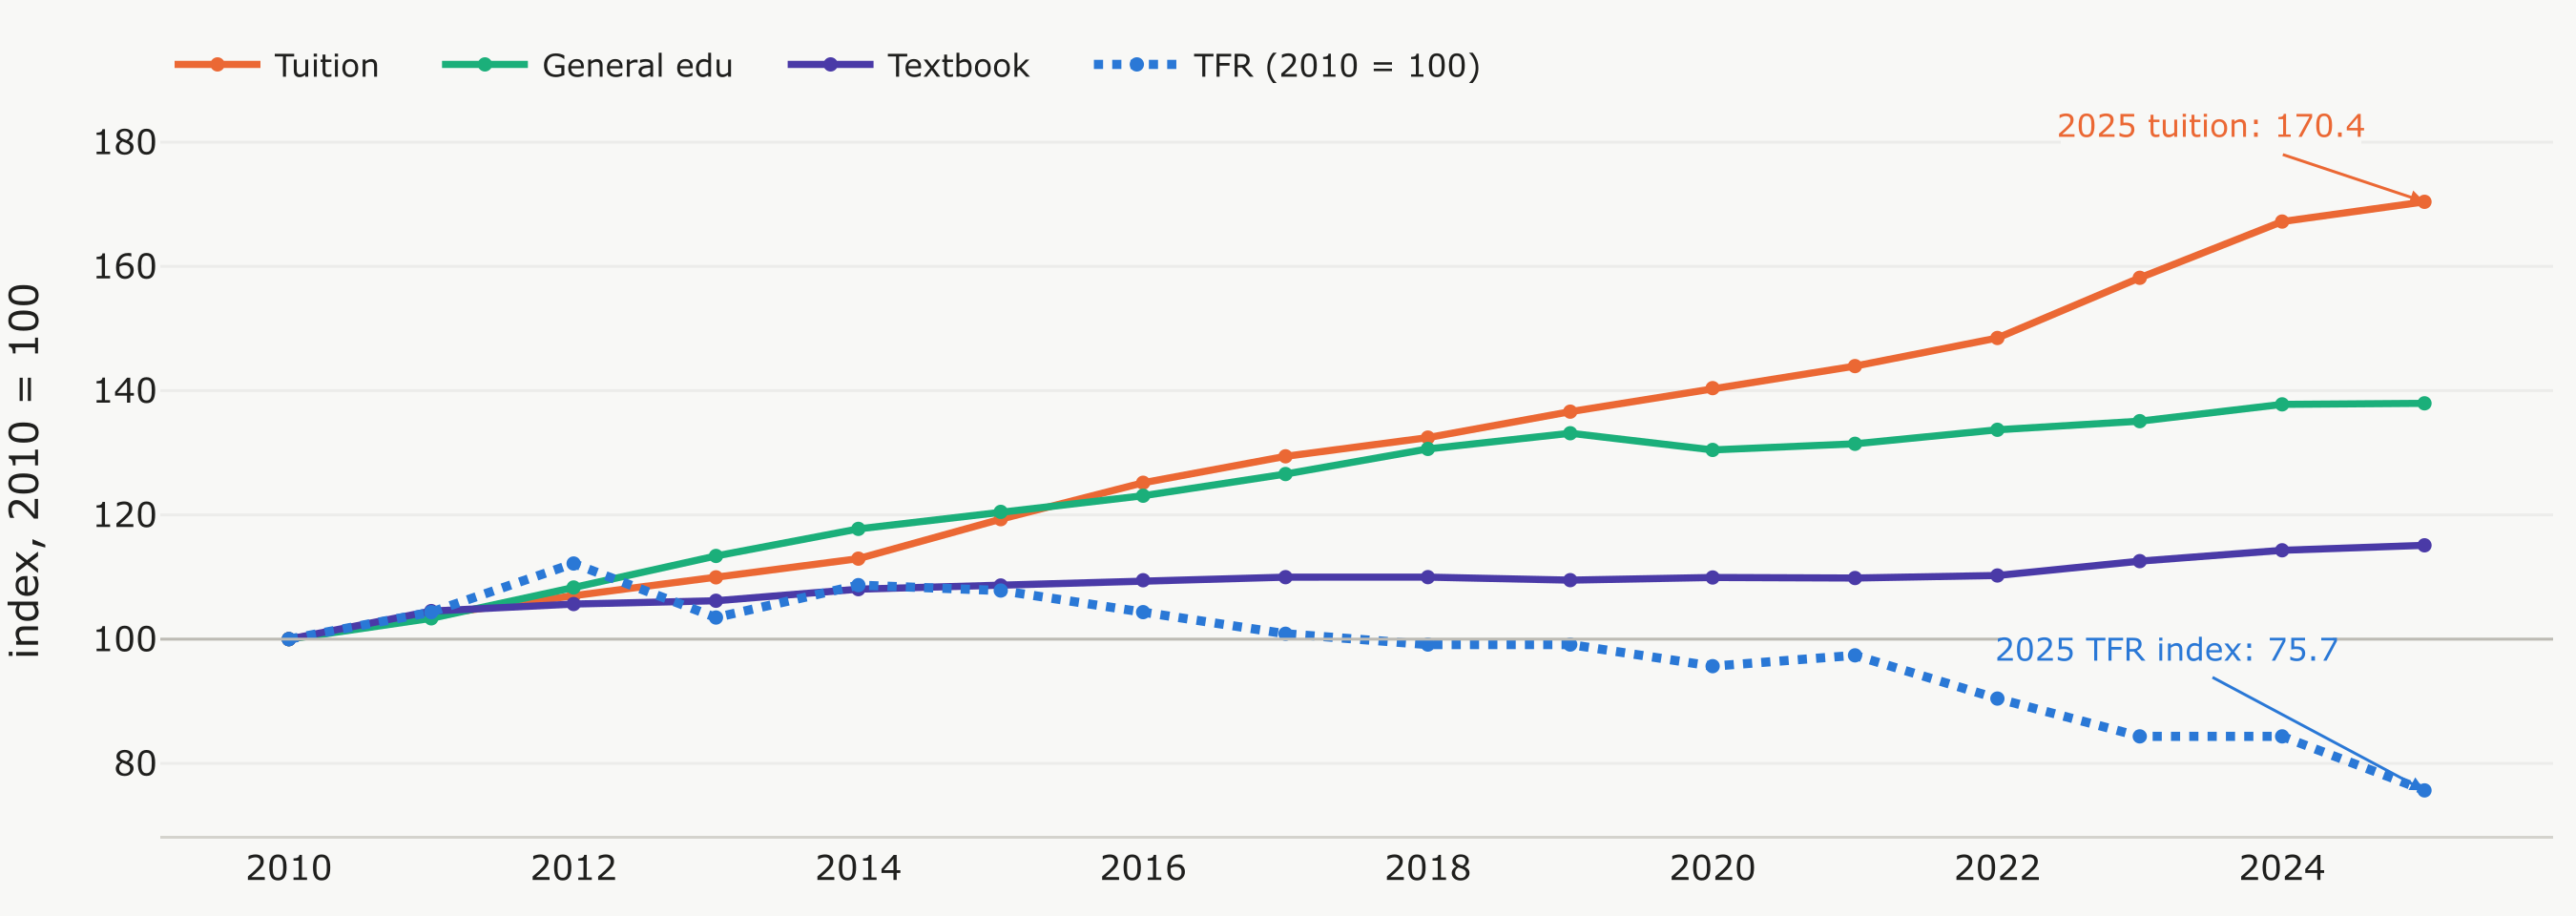

In [43]:
c1, c2 = st.columns(2)
with c1, card("Education prices"):
    show(index_lines(df, list(CPI), CPI, {c: short(c).replace(" prices", "") for c in CPI}, h=320))
    note("Tuition: " + trend(df, "Edu_CPI_Tuition", "{:.0f}"), "2010 = 100", src("Edu_CPI", "TFR"))



**Insight:** Tuition prices rose 70.4%, while TFR fell 24.3% from 2010 to 2025. Higher education costs may add to the expected cost of raising a child.

## 2. Education price changes

Source: SingStat M213801. Policy context: SingStat CPI paper and IRAS GST guidance.

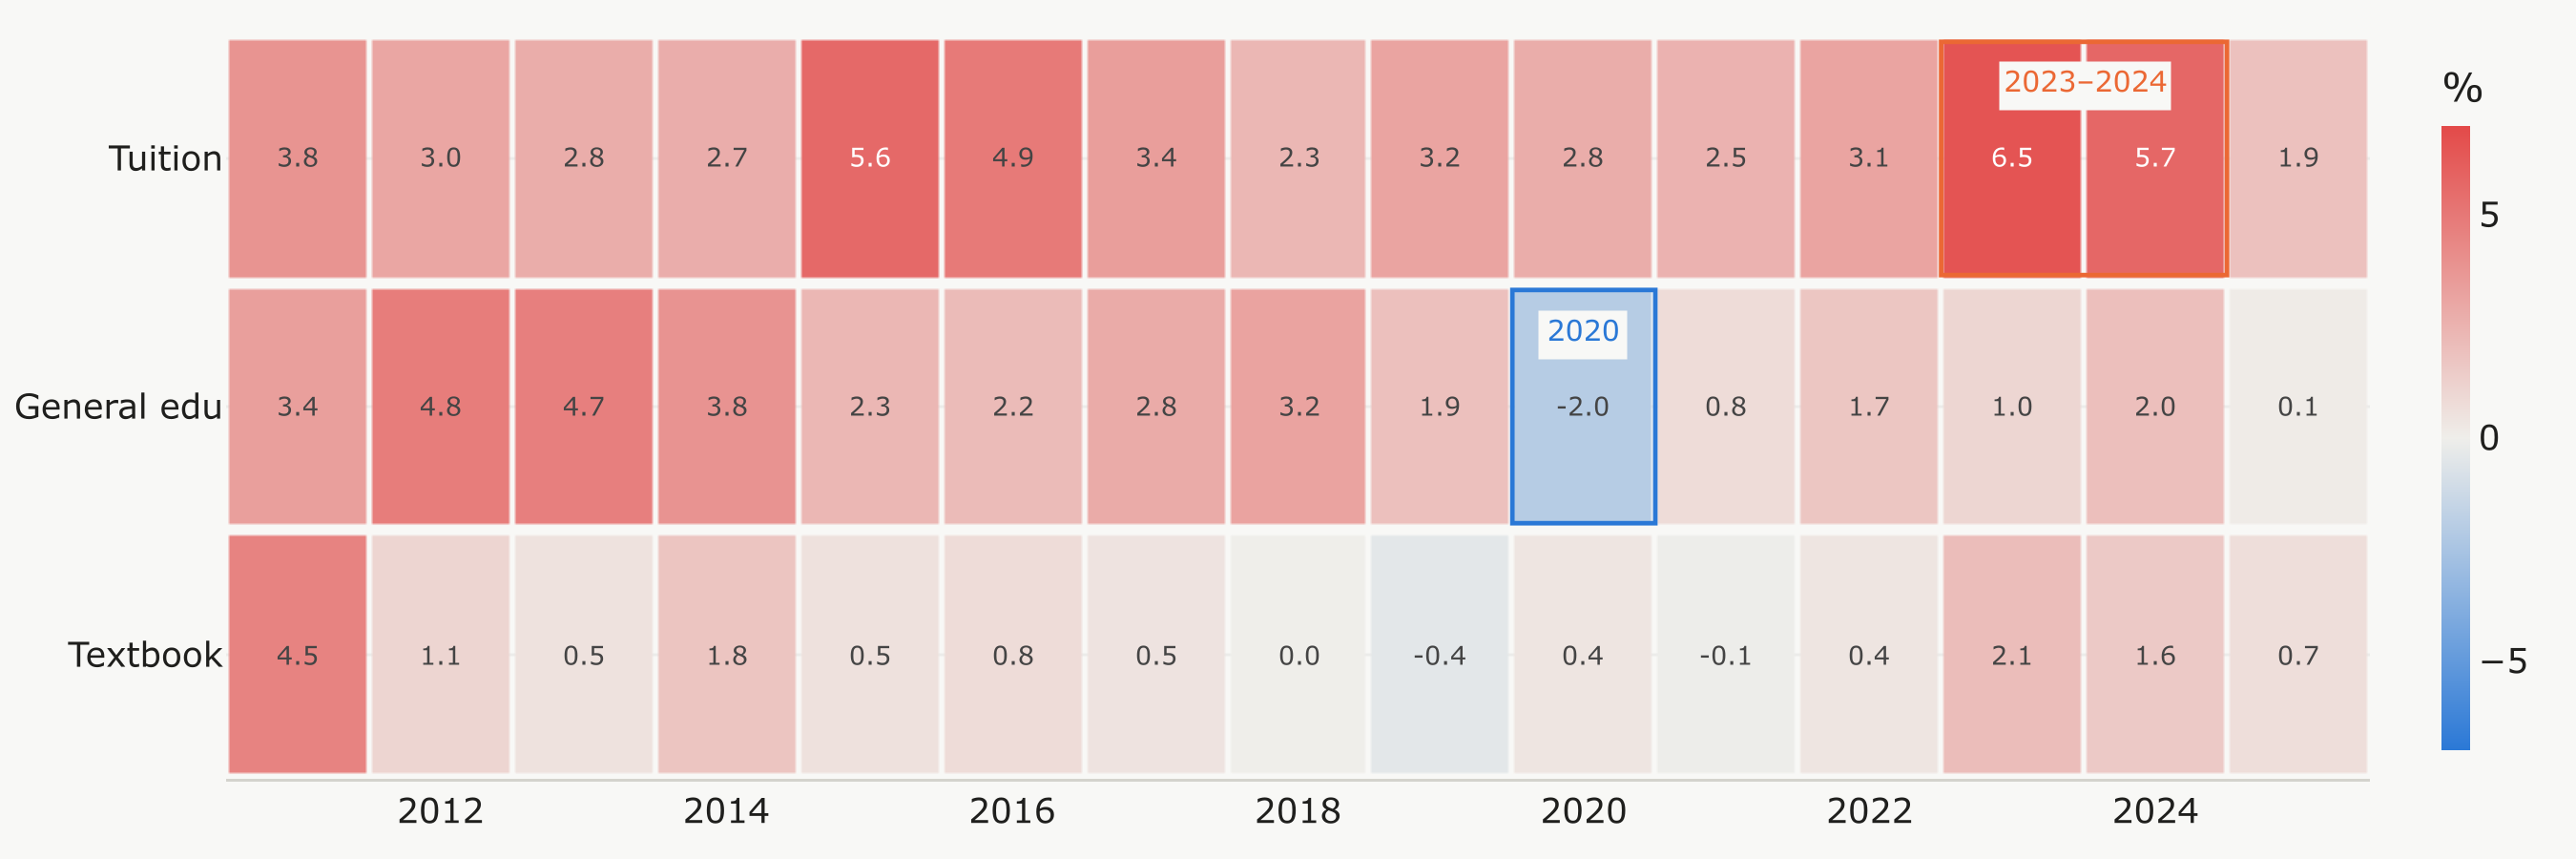

In [44]:
with c2, card("When prices rose or fell"):
    z = e.set_index("Year")[list(CPI)].pct_change().mul(100).dropna(how="all").T
    fig = go.Figure(go.Heatmap(z=z.values, x=z.columns, y=[short(c).replace(" prices", "") for c in CPI],
                               colorscale=[[0, "#2a78d6"], [0.5, "#efeeea"], [1, "#e34948"]], zmin=-7, zmax=7, xgap=2, ygap=4,
                               text=np.round(z.values, 1), texttemplate="%{text:.1f}", textfont=dict(size=9),
                               colorbar=dict(title="%", thickness=10), hovertemplate="%{y}, %{x}: %{z:+.1f}%<extra></extra>"))
    fig.update_yaxes(autorange="reversed")
    show(style(fig, 320, legend=False, hover="closest"))
    note("annual % change in each price index", src("Edu_CPI"))



**Insight:** General education prices fell 2.0% in 2020, alongside enhanced preschool subsidies. Tuition prices rose sharply in 2023–2024.

## 3. Government spending per student

Source: SingStat M850291. Nominal S$, financial years.

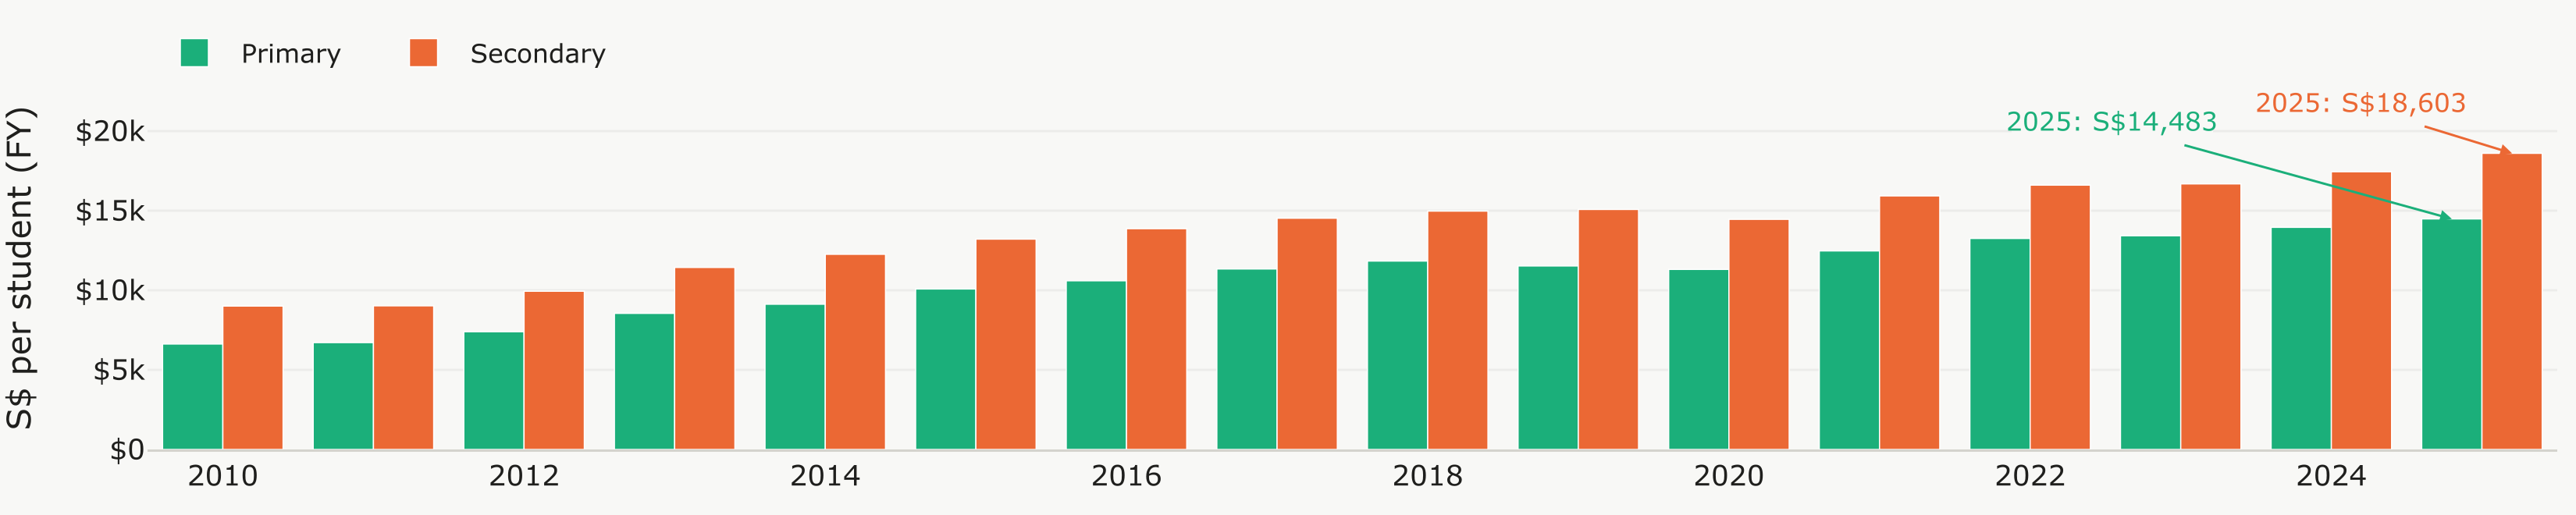

In [45]:
c3, c4 = st.columns(2)
with c3, card("Government spending per student"):
    d = df.dropna(subset=["Edu_Primary_per_Student"])
    fig = go.Figure()
    for c, n, col in [("Edu_Primary_per_Student", "Primary", AQUA), ("Edu_Secondary_per_Student", "Secondary", ORANGE)]:
        fig.add_trace(go.Bar(x=d.Year, y=d[c], name=n, marker_color=col, hovertemplate="FY%{x} " + n + ": S$%{y:,.0f}<extra></extra>"))
    fig.update_layout(barmode="group", bargap=0.2)
    fig.update_yaxes(title_text="S$ per student (FY)", tickprefix="$")
    show(style(fig, 300, hover="closest"))
    note("Primary: " + trend(df, "Edu_Primary_per_Student", "${:,.0f}"), "financial years", "click a bar to focus",
         src("Edu_Primary_per_Student"))



**Insight:** Public spending per pupil more than doubled in both primary and secondary education.

## 4. Education budget allocation

Source: SingStat M850011. FY2025 revised estimates.

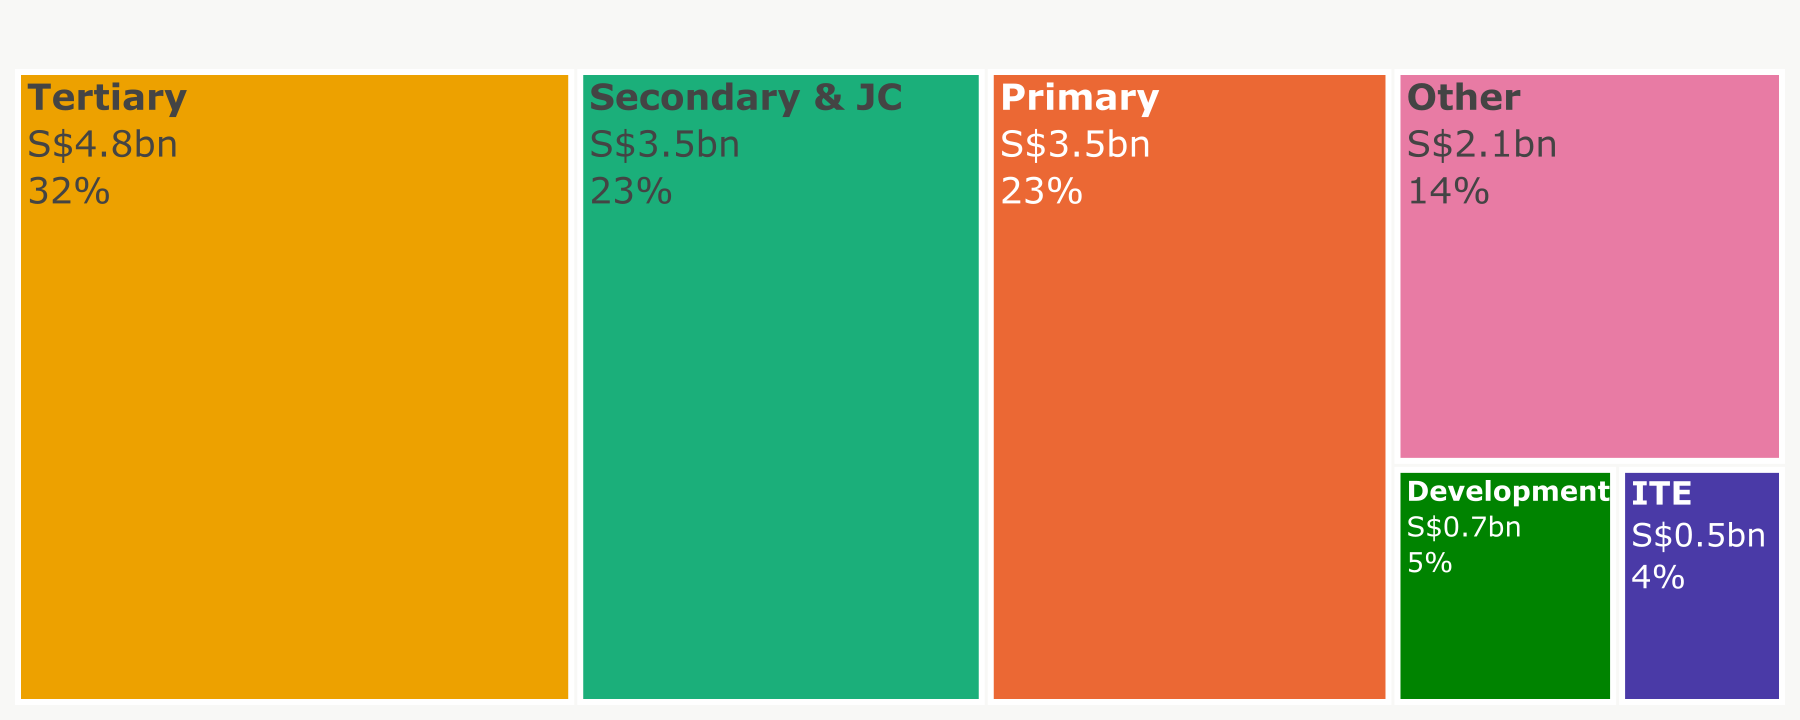

In [46]:
with c4, card("Where education funding goes"):
    OPS = {"Edu_Op_Primary": "Primary", "Edu_Op_Secondary_JC": "Secondary & JC", "Edu_Op_ITE": "ITE",
           "Edu_Op_Tertiary": "Tertiary", "Edu_Op_Other": "Other", "Edu_Development": "Development"}
    yrs = df.dropna(subset=list(OPS)).Year.astype(int).tolist()
    yr = st.select_slider("Year", yrs, value=yrs[-1], key="edu_tree", label_visibility="collapsed")
    v = df.set_index("Year").loc[yr, list(OPS)] / 1000
    fig = go.Figure(go.Treemap(labels=list(OPS.values()), parents=[""] * len(OPS), values=v.values,
                               marker=dict(colors=SERIES[:6], line=dict(color="white", width=2)),
                               texttemplate="<b>%{label}</b><br>S$%{value:.1f}bn<br>%{percentRoot:.0%}",
                               hovertemplate="%{label}: S$%{value:.2f}bn<extra></extra>"))
    show(style(fig, 280, legend=False, hover="closest").update_layout(margin=dict(l=0, r=0, t=0, b=0)))
    note(f"FY{yr} total S${v.sum():.1f}bn", src("Edu_Public_Total"))



**Insight:** Primary and secondary/JC received 46.1% of FY2025 education funding. Together with higher spending per pupil, this shows sustained public support for schooling within a wider education budget.

## 5. Education prices and TFR

Source: SingStat M213801 and M810091. Pearson r and two-sided p-values use 16 annual level observations from 2010 to 2025.


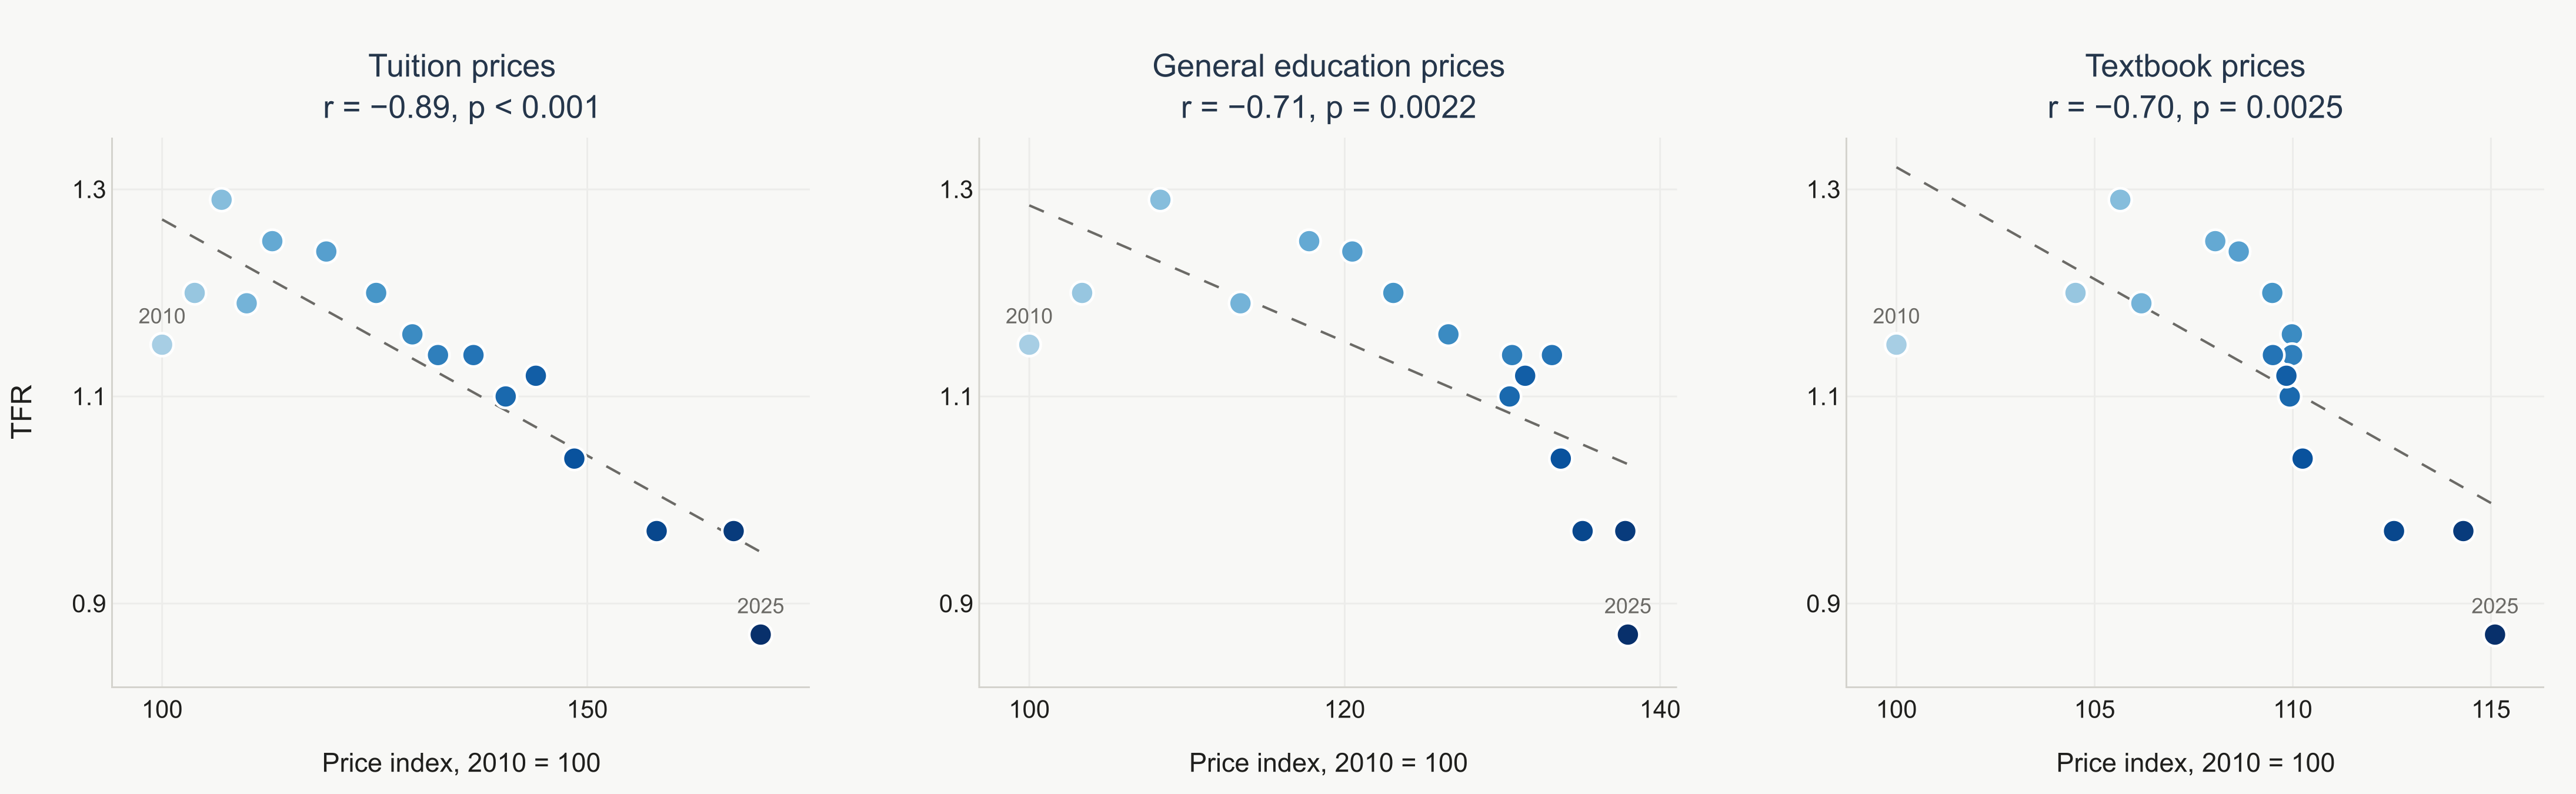

In [47]:
from pathlib import Path
import copy

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from scipy.stats import pearsonr
from plotly.subplots import make_subplots

BASE = Path.cwd()
df = load_section('education')   # combined notebook: read from Fertility_Combined_Data.csv
df = df[df.Year.between(2010, 2025)]
reference = pio.read_json(BASE / 'figures/05_tfr.json')

factors = [
    ('Edu_CPI_Tuition', 'Tuition prices', 'Price index, 2010 = 100'),
    ('Edu_CPI_General', 'General education prices', 'Price index, 2010 = 100'),
    ('Edu_CPI_Textbooks', 'Textbook prices', 'Price index, 2010 = 100'),
]

statistics = {}
for column, title, unit in factors:
    pair = df[[column, 'TFR']].dropna()
    result = pearsonr(pair[column], pair.TFR, alternative='two-sided')
    statistics[column] = {'r': float(result.statistic), 'p': float(result.pvalue), 'n': len(pair)}

titles = []
for column, title, unit in factors:
    stats = statistics[column]
    r_text = f"{stats['r']:.2f}".replace('-', '−')
    p_text = 'p < 0.001' if stats['p'] < 0.001 else f"p = {stats['p']:.4f}"
    titles.append(f'{title}<br>r = {r_text}, {p_text}')

fig = make_subplots(
    rows=1, cols=3, shared_yaxes=True,
    horizontal_spacing=0.07,
    subplot_titles=titles,
)
chart_data = {}
for i, (column, title, unit) in enumerate(factors):
    row, col = divmod(i, 3)
    row, col = row + 1, col + 1
    d = df[['Year', column, 'TFR']].dropna()
    years = d.Year.to_numpy()
    x = d[column].to_numpy()
    y = d.TFR.to_numpy()
    slope, intercept = np.polyfit(x, y, 1)
    fitted_x = np.linspace(x.min(), x.max(), 30)

    # Reuse the original scatter's trace styling and year colour mapping.
    fitted = go.Scatter(copy.deepcopy(reference.data[0].to_plotly_json()))
    fitted.update(x=fitted_x, y=intercept + slope * fitted_x)
    points = go.Scatter(copy.deepcopy(reference.data[1].to_plotly_json()))
    points.update(
        x=x, y=y, customdata=years,
        text=[str(year) if year in {years.min(), years.max()} else '' for year in years],
        hovertemplate='<b>%{customdata}</b><br>' + title + ': %{x:,.2f}<br>TFR: %{y:,.3f}<extra></extra>',
    )
    # A larger label font keeps the original endpoint years legible in the comparison.
    points.textfont.size = 12
    fig.add_trace(fitted, row=row, col=col)
    fig.add_trace(points, row=row, col=col)
    fig.update_xaxes(
        title_text=unit, title_font_size=15, tickfont_size=14,
        showgrid=True, gridcolor='#ececea', linecolor='#d4d3cd', zeroline=False,
        nticks=4, row=row, col=col,
    )
    fig.update_yaxes(
        range=[0.82, 1.35], tickvals=[0.9, 1.1, 1.3], tickformat='.1f',
        title_text='TFR' if col == 1 else None,
        title_font_size=16, tickfont_size=14, showticklabels=True,
        gridcolor='#ececea', linecolor='#d4d3cd', zeroline=False,
        row=row, col=col,
    )
    chart_data[column] = {'years': years.tolist(), 'x': x.tolist(), 'tfr': y.tolist(), 'pearson_r': statistics[column]['r'], 'p_value': statistics[column]['p'], 'n': statistics[column]['n']}

fig.update_layout(
    width=1460, height=450, template='plotly_white', showlegend=False,
    margin=dict(l=64, r=18, t=78, b=50),
    font=dict(family='Arial', size=15, color='#1f1f1d'),
    paper_bgcolor='#F8F8F6', plot_bgcolor='#F8F8F6', hovermode='closest',
)
fig.update_annotations(font=dict(family='Arial', size=18, color='#25364B'))
fig.write_json(BASE / 'figures/05_education_factors.json')

figures["05_education_factors"] = fig
display(Image(filename=str(BASE / "figures/05_education_factors.png"), width=1200))


**Insight:** Tuition: r = −0.89, p < 0.001. General education: r = −0.71, p = 0.0022. Textbooks: r = −0.70, p = 0.0025.
